# Installing Net2Brain

<img src="workshops/data/Net2Brain_Logo.png" width="25%" />

In [1]:
#!pip install -U git+https://github.com/cvai-roig-lab/Net2Brain

# Representational Similiratiy Analysis (RSA) Evaluation

First load the ROIs

In [1]:
from net2brain.utils.download_datasets import DatasetAlgonauts_NSD_Shared
from pprint import pprint
import os
import numpy as np
import pandas as pd

#paths_bonner = DatasetBonnerPNAS2017.load_dataset()
#stimuli_path = paths_bonner["stimuli_path"]
#roi_path = paths_bonner["roi_path"]



paths_NSD_shared  = DatasetAlgonauts_NSD_Shared.load_dataset()
stimuli_path = paths_NSD_shared["images"]



RSA format expects: (subjects, images, images). if one subject: (1,img,img)  
works on consolidated features (each .npz files represents a layer)
results explaination:
ROI: brain region 
Layer:  
Model:  
R2: how well the model explains brain activity. 0->0.1  
%R2: performance relative to noise ceiling. 45% = model explains half of what is explainable  
R2_array_  
Sig: p-value. < 0.05 → significant   
SEM: error   
LNC: Noise ceilings: lower bound  
UNC: upper bound  


In [1]:
from net2brain.evaluations.rsa import RSA

model_rdms = "PATH" 

brain_rdms = "PATH" # combined l+r hemosphere
#brain_rdms = "PATH" # non combined
#print(brain_rdms)

# Start RSA
evaluation = RSA(model_rdms, brain_rdms, model_name="CLIP_cls", squared=True)

# Evaluation - Returns a pandas dataframe
dataframe1 = evaluation.evaluate() 

# Show results
display(dataframe1)

#save results as csv
dataframe1.to_csv("PATH", index=False)
#dataframe1.to_csv("PATH", index=False)



FileNotFoundError: [WinError 3] The system cannot find the path specified: 'PATH'

Optional RSA class arguments to consider:
- Argument `layer_skips` to skip certain layers during 
evaluation. This can be
useful when you have a large number of layers extracted and want to test only a subset of them.
- By default the evaluation returns the squared correlations. If you don't want to square the 
correlations, you
should set `squared=False`. This is different from later changing the metric in plotting, as 
correlations are
subject-averaged by then, and also negative correlations cannot be recovered.
- If your neural data is temporal (EEG/MEG), you can specify whether to average across timepoints
 with `timepoint_agg`. By default this is set to True, meaning that the neural RDMs are averaged 
 across timepoints before RSA. If you want to perform RSA at each timepoint separately, set this to False.
- If your video models contain timepoints (e.g. video models features extracted in a 
time-resolved manner and converted to time-resolved RDMs as shown in previous notebooks), you 
should specify this by setting `model_timepoints=True`. By default this is set to False.

In [14]:
# cleaning clip df
import pandas as pd

path = "PATH"

df = pd.read_csv(path)

print("Before:", len(df))

df = df.dropna(subset=["R2"]).reset_index(drop=True)

print("After:", len(df))
print("Removed:", len(pd.read_csv(path)) - len(df))

df.to_csv(path, index=False)

print("Saved cleaned file.")

Before: 435
After: 225
Removed: 210
Saved cleaned file.


## Visualizing RSA Evaluation Results

### Visualizing RSA Evaluation Results one model

The integrated plotting functionality of the toolbox allows you to easily visualize evaluation results. To achieve this, initialize the class with a list of DataFrames obtained from the evaluation. Make sure that each DataFrame:

1. Contains the same ROIs, signifying that each test was performed on the same brain RDMs.
2. Has a distinct model name, which can be set manually or through the "model_name" parameter during evaluation (as mentioned earlier).

Here's an example of how to plot the data using a single DataFrame:

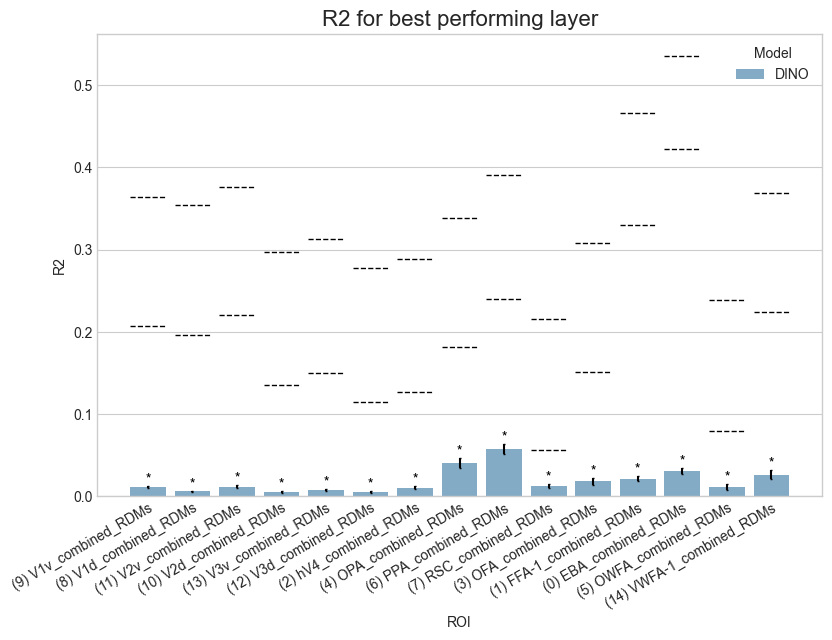

In [2]:
from net2brain.evaluations.plotting import Plotting

plotter = Plotting([dataframe_dino_combined])
results_dataframe = plotter.plot()

In [4]:
print(dataframe_dino_combined["ROI"].unique())

['(0) EBA_combined_RDMs' '(1) FFA-1_combined_RDMs' '(2) hV4_combined_RDMs'
 '(3) OFA_combined_RDMs' '(4) OPA_combined_RDMs' '(5) OWFA_combined_RDMs'
 '(6) PPA_combined_RDMs' '(7) RSC_combined_RDMs' '(8) V1d_combined_RDMs'
 '(9) V1v_combined_RDMs' '(10) V2d_combined_RDMs' '(11) V2v_combined_RDMs'
 '(12) V3d_combined_RDMs' '(13) V3v_combined_RDMs'
 '(14) VWFA-1_combined_RDMs']


In [1]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting


plotter = Plotting([dataframe_dino_combined])
results_dataframe = plotter.plot(metric="R")

NameError: name 'dataframe_dino_combined' is not defined

You can choose between `metric="R2"` (default) or `metric="R"`

You can also choose between plotting the best layers or `plot_all_layers()`.

In [ ]:
results_dataframe = plotter.plot_all_layers(metric="R2")

### Visualizing RSA Evaluation Results - Multiple models

As previously mentioned, you can also plot multiple models in a single plot. To do this, simply include additional DataFrames in the list:

        Plotting([dataframe1, dataframe2, dataframe3])



### Vision-Language Models 
 VLJEPA  
 InfoNCE  
 OpenClip  
 Net2brain clip  

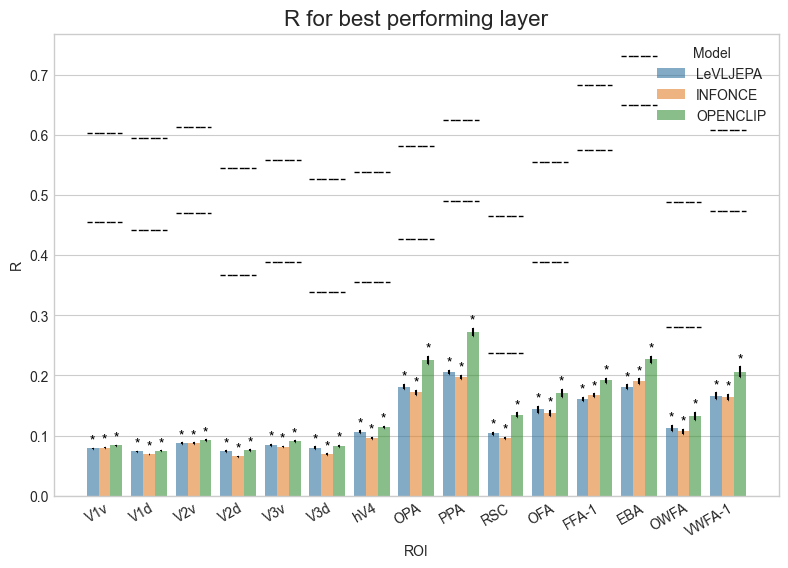

In [7]:

import pandas as pd
from net2brain.evaluations.plotting import Plotting



dataframe_levljepa = pd.read_csv(
    "PATH"
)

dataframe_clip = pd.read_csv(
    "PATH"
)

dataframe_infonce = pd.read_csv(
    "PATH"
)

dataframe_openclip = pd.read_csv(
    "PATH"
)

plotter = Plotting([
    dataframe_levljepa,
    dataframe_infonce,
    dataframe_openclip
])

results_dataframe = plotter.plot(
    metric='R',
    save_path="PATH"
)

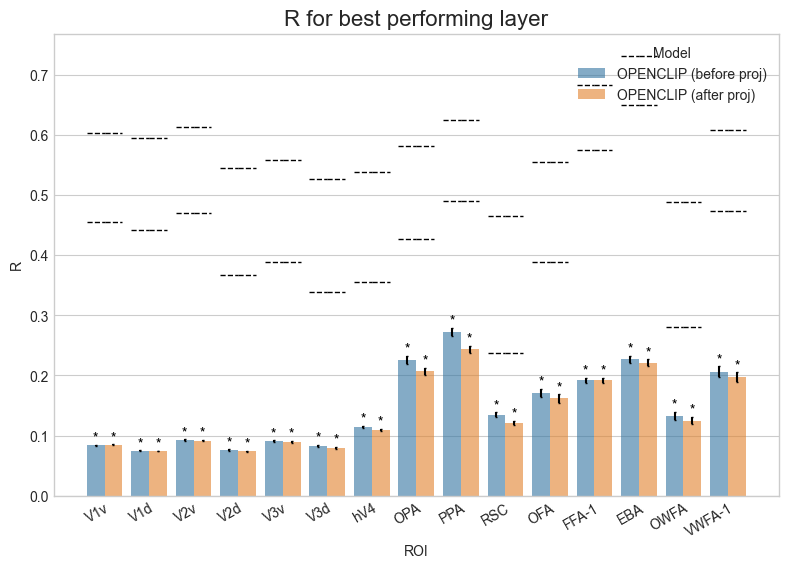

In [8]:
# testing open clips proj

from net2brain.evaluations.plotting import Plotting
import pandas as pd


dataframe_openclip_cls = pd.read_csv("PATH")
dataframe_openclip_an_cls_bproj = pd.read_csv("PATH")

plotter = Plotting([  dataframe_openclip_cls , dataframe_openclip_an_cls_bproj])
results_dataframe = plotter.plot(metric = 'R', save_path="PATH"])


### Self-Supervised Models vit-L 16  
Mae  
IBOT   
Lejepa


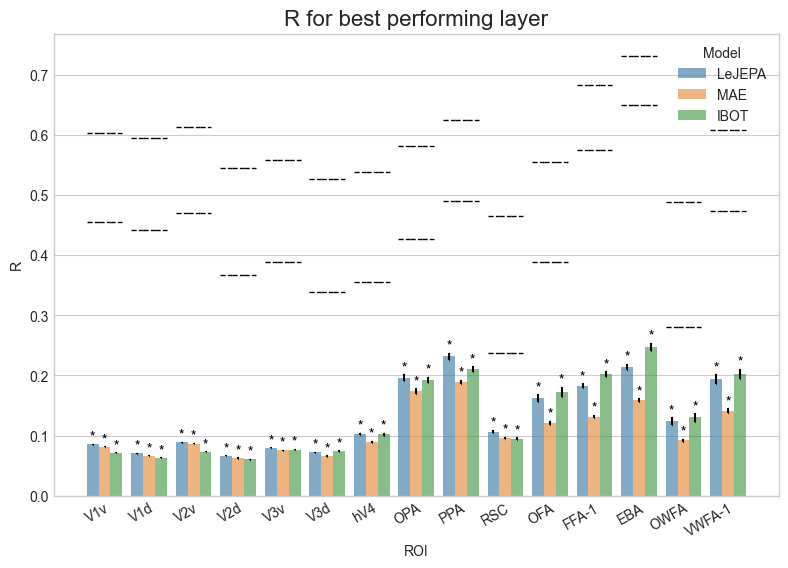

In [11]:

from net2brain.evaluations.plotting import Plotting
import pandas as pd
dataframe_ibot_cls = pd.read_csv("PATH")
dataframe_lejepa_cls = pd.read_csv("PATH")

dataframe_mae_cls = pd.read_csv("PATH")

plotter = Plotting([ dataframe_lejepa_cls ,  dataframe_mae_cls , dataframe_ibot_cls ])
results_dataframe = plotter.plot(metric = 'R',save_path="PATH"])



### Self-Supervised Models vit-B 16  
Dinov1  
Lejepa from lukas  

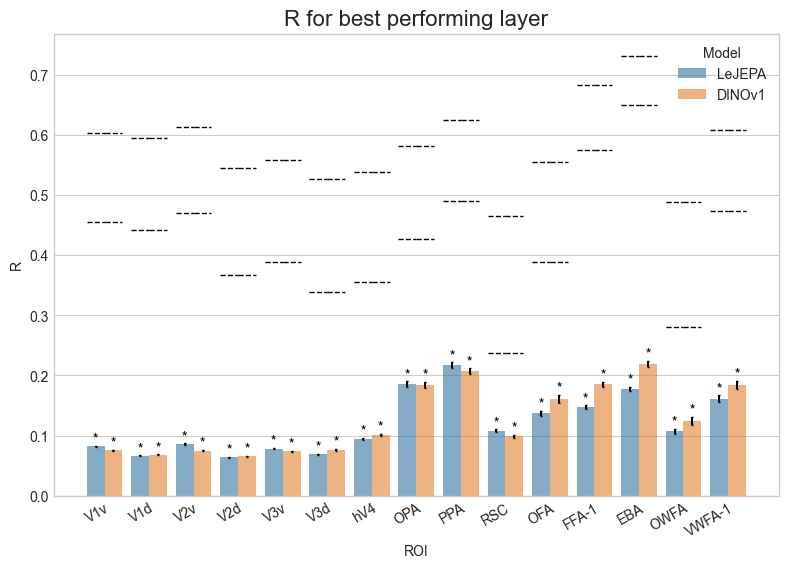

In [12]:

import pandas as pd
from net2brain.evaluations.plotting import Plotting



dataframe_dinov1 = pd.read_csv(
    "PATH"
)


dataframe_lejepa = pd.read_csv(
    "PATH"
)



plotter = Plotting([
    dataframe_lejepa,
    dataframe_dinov1
])

results_dataframe = plotter.plot(
    metric='R',
    save_path="PATH"
)

all vitb:

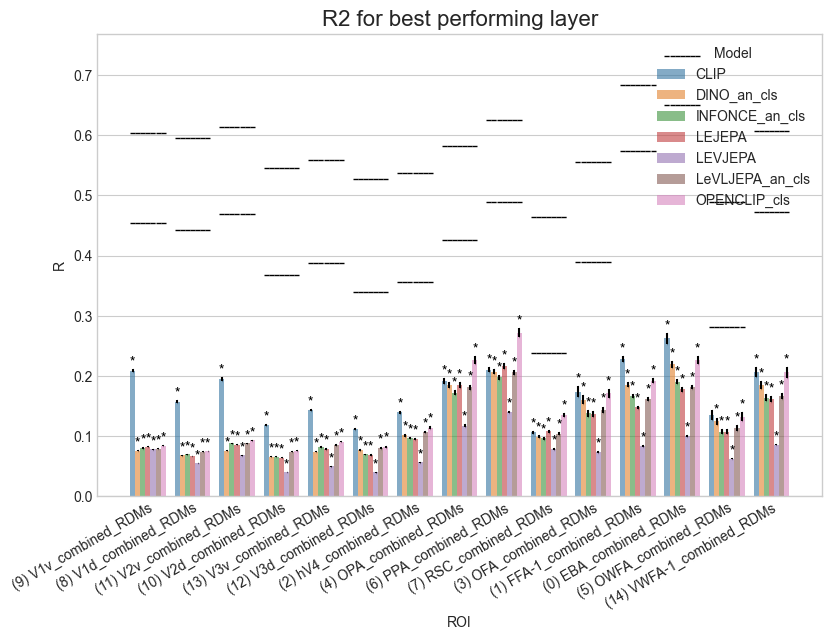

In [7]:

import pandas as pd
from net2brain.evaluations.plotting import Plotting



dataframe_dinov1 = pd.read_csv(
    "PATH"
)

dataframe_clip = pd.read_csv(
    "PATH"
)

dataframe_infonce = pd.read_csv(
    "PATH"
)

dataframe_openclip = pd.read_csv(
    "PATH"
)

dataframe_lejepa = pd.read_csv(
    "PATH"
)

dataframe_levjepa = pd.read_csv(
    "PATH"
)

dataframe_levljepa = pd.read_csv(
    "PATH"
)

dataframe_openclip = pd.read_csv(
    "PATH"
)

plotter = Plotting([
    dataframe_clip,
    dataframe_dinov1,
    dataframe_infonce,
    dataframe_lejepa,
    dataframe_levjepa,
    dataframe_levljepa,
    dataframe_openclip
])

results_dataframe = plotter.plot(
    metric='R',
    save_path="PATH"
)

### video models

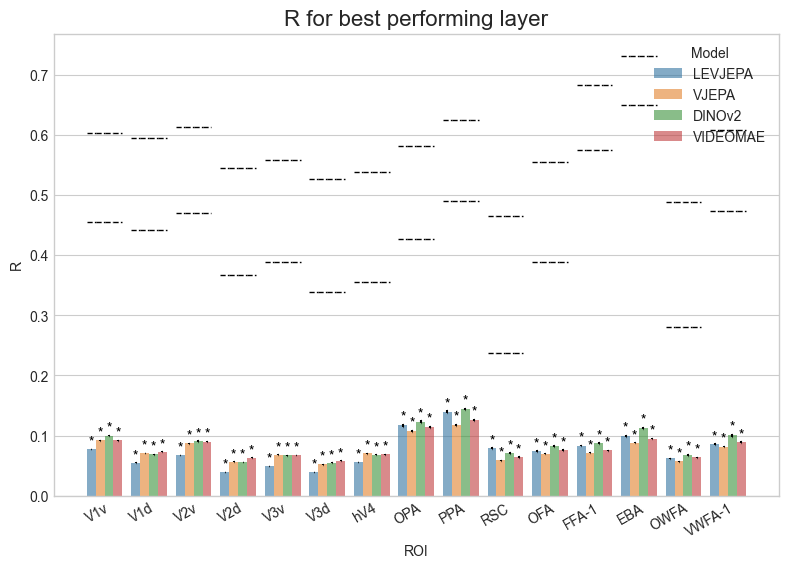

In [13]:

import pandas as pd
from net2brain.evaluations.plotting import Plotting

dataframe_dinov2_video = pd.read_csv(
    "PATH"
)

dataframe_video_mae = pd.read_csv(
    "PATH"
)

dataframe_vjepa = pd.read_csv(
    "PATH"
)

dataframe_levjepa = pd.read_csv(
    "PATH"
)

plotter = Plotting([
    dataframe_levjepa,
    dataframe_vjepa,
    dataframe_dinov2_video,
    dataframe_video_mae,
    
])

results_dataframe = plotter.plot(
    metric='R',
    save_path="PATH"
)

### extra plots

#### CLS vs mean pooling

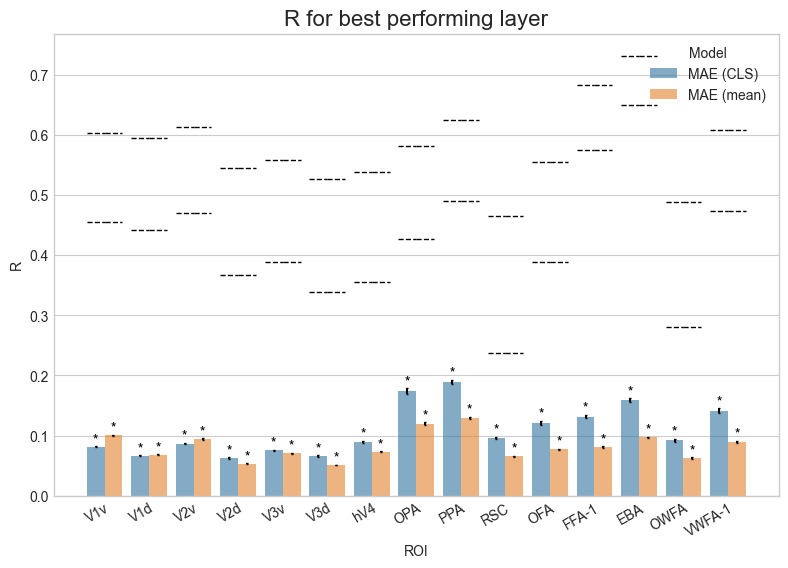

In [14]:
from net2brain.evaluations.plotting import Plotting

import pandas as pd

dataframe_mae_an_cls = pd.read_csv("PATH")
dataframe_mae = pd.read_csv("PATH")
plotter = Plotting([   dataframe_mae_an_cls, dataframe_mae])
results_dataframe = plotter.plot(metric = 'R', save_path="PATH", model_names=['MAE (CLS)','MAE (mean)'])

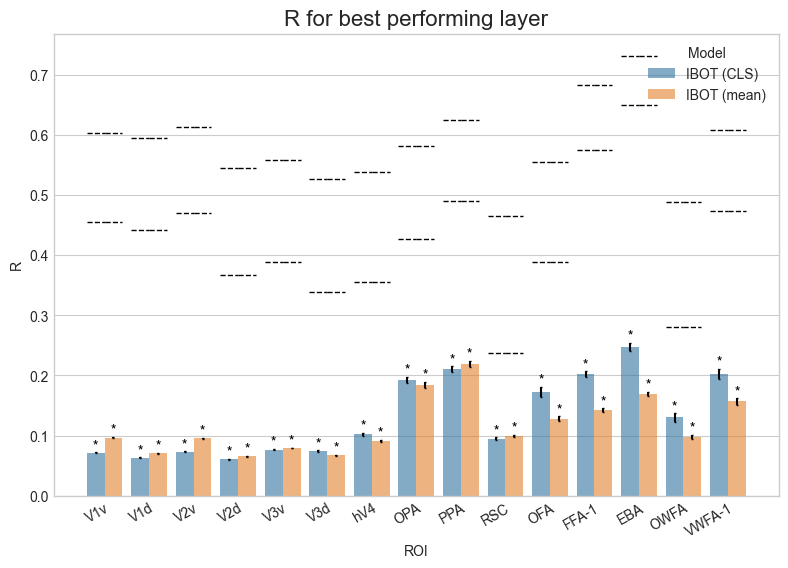

In [17]:
from net2brain.evaluations.plotting import Plotting

dataframe_ibot_combined = pd.read_csv("PATH")
dataframe_ibot_combined_an_cls = pd.read_csv("PATH")
plotter = Plotting([ dataframe_ibot_combined_an_cls,  dataframe_ibot_combined])
results_dataframe = plotter.plot(metric = 'R', save_path="PATH", model_names=['IBOT (CLS)','IBOT (mean)'])

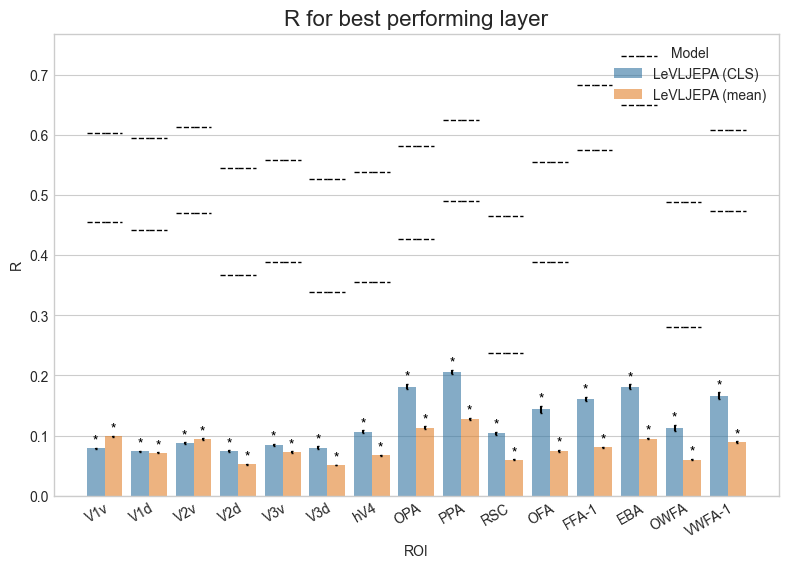

In [18]:
# CLS token vs Mean Pooling
from net2brain.evaluations.plotting import Plotting
import pandas as pd

dataframe_LeVLJEPA = pd.read_csv("PATH")
dataframe_LeVLJEPA_CLS = pd.read_csv("PATH")

plotter = Plotting([  dataframe_LeVLJEPA_CLS, dataframe_LeVLJEPA])
results_dataframe = plotter.plot(metric = 'R',save_path="PATH",model_names=['LeVLJEPA (CLS)','LeVLJEPA (mean)'])

# Last Layers vs all Layers vs best layer

#### post-norms vs pre-norms

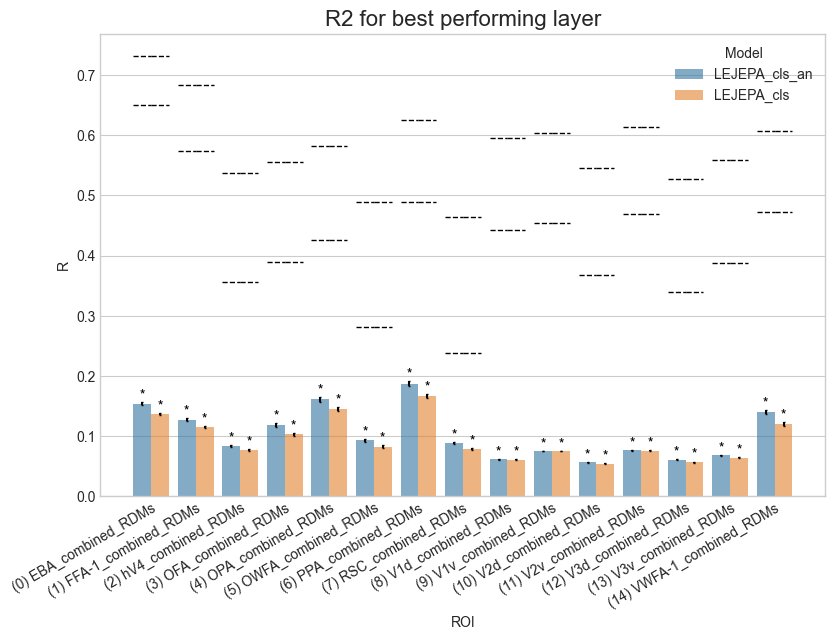

In [11]:
#before or after layernorm. not sure what i used. maybe cls
plotter = Plotting([  dataframe_lejepa_combined_cls_afternorms, dataframe_lejepa_combined_cls])
results_dataframe = plotter.plot(metric = 'R')

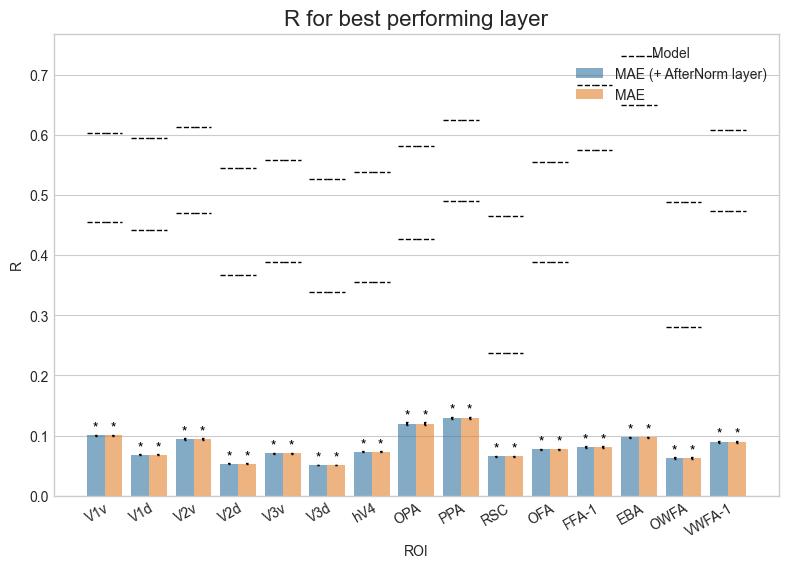

In [20]:
dataframe_mae_an = pd.read_csv("PATH")
dataframe_mae = pd.read_csv("PATH")

plotter = Plotting([  dataframe_mae_an, dataframe_mae])
results_dataframe = plotter.plot(metric = 'R',save_path="PATH",model_names=['MAE (+ AfterNorm layer)','MAE '])

In [ ]:
plotter = Plotting([  dataframe_mae_an, dataframe_mae])
results_dataframe = plotter.plot(metric = 'R')

In [6]:
# calc. RSA for first model
model_rdms = "PATH" 

brain_rdms = "PATH" #combined
#brain_rdms = "PATH" #non combined

evaluation_1 = RSA(model_rdms, brain_rdms, model_name="MAE", squared=True)

# calc. RSA for second model
model_rdms = "PATH" 

brain_rdms = "PATH" #combined
#brain_rdms = "PATH" #non combined

evaluation_2 = RSA(model_rdms, brain_rdms, model_name="JEPA", squared=True)

# Comparing statistical significance
ttest, sig_pairs = evaluation_1.compare_model(evaluation_2)
print(sig_pairs)

# Plotting with significance
plotter = Plotting([dataframe_jepa_combined,dataframe_mae_combined])
results_dataframe = plotter.plot(pairs=sig_pairs)

AttributeError: 'RSA' object has no attribute 'distance_metric'

In [25]:
from scipy import stats
import numpy as np

mae_row = best_mae.loc["best layer ROI RDM"]
jepa_row = best_jepa.loc["best layer ROI RDM"]
# get the R2 values and put them in lists
mae_arr = np.fromstring(
    mae_row["R2_array"].strip("[]"),
    sep=" "
)

jepa_arr = np.fromstring(
    jepa_row["R2_array"].strip("[]"),
    sep=" "
)
# perform the test
t_stat, p_value = stats.ttest_rel(jepa_arr, mae_arr)

print("t =", t_stat)
print("p =", p_value)
print("MAE mean =", mae_arr.mean())
print("iJEPA mean =", jepa_arr.mean())

t = 8.85032620096635
p = 4.756699452281654e-05
MAE mean = 0.009439122500000001
iJEPA mean = 0.034460988750000004


In [7]:
import os
import numpy as np
import pandas as pd
from net2brain.evaluations.variance_partitioning_analysis import VPA


# ============================================================
# SETTINGS
# ============================================================

model1 = "IBOT"
model2 = "LEJEPA"


# ============================================================
# RSA RESULTS
# Used ONLY to select the best layer for each ROI
# ============================================================

best_model1 = (
    dataframe_ibot
    .sort_values("R2", ascending=False)
    .groupby("ROI")
    .first()
)

best_model2 = (
    dataframe_lejepa
    .sort_values("R2", ascending=False)
    .groupby("ROI")
    .first()
)


# ============================================================
# MODEL RDM LOCATIONS
# ============================================================

rdm_paths = {
    "IBOT": "PATH",
    "LEJEPA": "PATH"
}


rdm_model1 = rdm_paths[model1]
rdm_model2 = rdm_paths[model2]


# ============================================================
# BRAIN RDM LOCATION
# ============================================================

brain_rdms = "PATH"


# ============================================================
# RUN RSA UVP
# ============================================================

all_results = []


for roi in best_model1.index:

    print(f"Processing {roi}...")

    # --------------------------------------------------------
    # Best RSA layer for each model
    # --------------------------------------------------------

    model1_row = best_model1.loc[roi]
    model2_row = best_model2.loc[roi]

    model1_layer = model1_row["Laye"PATH", 1)[1]
    model2_layer = model2_row["Laye"PATH", 1)[1]

    print(f"  {model1}: {model1_layer}")
    print(f"  {model2}: {model2_layer}")


    # --------------------------------------------------------
    # Model RDM paths
    # --------------------------------------------------------

    model1_rdm = os.path.join(rdm_model1, model1_layer)
    model2_rdm = os.path.join(rdm_model2, model2_layer)


    # --------------------------------------------------------
    # Brain RDM
    # --------------------------------------------------------

    roi_filename = roi.split(") ", 1)[1]

    brain_file = os.path.join(
        brain_rdms,
        roi_filename + ".npz"
    )


    # --------------------------------------------------------
    # Load brain RDM
    # --------------------------------------------------------

    x = np.load(
        brain_file,
        allow_pickle=True
    )["rdm"]


    # --------------------------------------------------------
    # Create VPA object
    # --------------------------------------------------------

    vpa = VPA(
        dependent_variable=[brain_file],
        independent_variables=[
            model1_rdm,
            model2_rdm
        ],
        variable_names=[
            model1,
            model2
        ]
    )


    # --------------------------------------------------------
    # Net2Brain workaround
    # --------------------------------------------------------

    vpa.independent_1 = [vpa.independent_1]
    vpa.independent_2 = [vpa.independent_2]

    vpa.average_models = False


    # --------------------------------------------------------
    # Convert brain RDMs to upper-triangular vectors
    # One vector per subject
    # --------------------------------------------------------

    dep_var = np.array([
        vpa.get_uppertriangular(subject)
        for subject in x
    ])

    dep_var = dep_var[:, None, :]


    # --------------------------------------------------------
    # Load model RDMs
    # --------------------------------------------------------

    vpa.load_rdms(vpa.independent_1)
    vpa.load_rdms(vpa.independent_2)


    # --------------------------------------------------------
    # Variance Partitioning
    # --------------------------------------------------------

    vp = vpa.VPA_function(
        dep_var,
        num_subjects=dep_var.shape[0],
        eeg_time=dep_var.shape[1]
    )


    # --------------------------------------------------------
    # Extract unique/shared variance
    # --------------------------------------------------------

    unique_model1_values = np.array(
        vp.loc[
            vp["Variable"] == "y1",
            "Values"
        ].iloc[0]
    ).flatten()

    shared_values = np.array(
        vp.loc[
            vp["Variable"] == "y12",
            "Values"
        ].iloc[0]
    ).flatten()

    unique_model2_values = np.array(
        vp.loc[
            vp["Variable"] == "y2",
            "Values"
        ].iloc[0]
    ).flatten()


    # --------------------------------------------------------
    # Means
    # --------------------------------------------------------

    unique_model1 = unique_model1_values.mean()
    shared = shared_values.mean()
    unique_model2 = unique_model2_values.mean()


    # --------------------------------------------------------
    # Standard deviations across subjects
    # --------------------------------------------------------

    unique_model1_std = unique_model1_values.std(ddof=1)
    shared_std = shared_values.std(ddof=1)
    unique_model2_std = unique_model2_values.std(ddof=1)


    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------

    all_results.append({

        "ROI": roi,

        f"Best_{model1}_Layer": model1_layer,
        f"Best_{model2}_Layer": model2_layer,

        f"{model1}_RSA_R2": model1_row["R2"],
        f"{model2}_RSA_R2": model2_row["R2"],

        f"Unique_{model1}": unique_model1,
        f"Unique_{model1}_STD": unique_model1_std,

        "Shared": shared,
        "Shared_STD": shared_std,

        f"Unique_{model2}": unique_model2,
        f"Unique_{model2}_STD": unique_model2_std
    })


# ============================================================
# CREATE RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(all_results)

display(results_df)


# ============================================================
# SAVE RESULTS
# ============================================================

output_folder = "PATH"

output_file = os.path.join(
    output_folder,
    f"rsa_uvp_{model1.lower()}_{model2.lower()}_all_rois.csv"
)

results_df.to_csv(
    output_file,
    index=False
)

print(f"\nResults saved to:\n{output_file}")

Processing (0) EBA_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_18.npz
Processing (1) FFA-1_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_18.npz
Processing (10) V2d_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_14.npz
Processing (11) V2v_combined_RDMs...
  IBOT: RDM_layer_8.npz
  LEJEPA: RDM_layer_10.npz
Processing (12) V3d_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_18.npz
Processing (13) V3v_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_14.npz
Processing (14) VWFA-1_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_18.npz
Processing (2) hV4_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_18.npz
Processing (3) OFA_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_19.npz
Processing (4) OPA_combined_RDMs...
  IBOT: RDM_layer_24_post_norm.npz
  LEJEPA: RDM_layer_18.npz
Processing (5) OWFA_c

,ROI,Best_IBOT_Layer,Best_LEJEPA_Layer,IBOT_RSA_R2,LEJEPA_RSA_R2,Unique_IBOT,Unique_IBOT_STD,Shared,Shared_STD,Unique_LEJEPA,Unique_LEJEPA_STD
0,(0) EBA_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_18.npz,0.060933,0.045904,0.015754,0.005056,0.051430,0.016214,0.006586,0.002205
1,(1) FFA-1_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_18.npz,0.040898,0.033453,0.008700,0.003180,0.035672,0.012243,0.006240,0.002470
2,(10) V2d_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_14.npz,0.003686,0.004388,0.000981,0.000722,0.003602,0.002309,0.001592,0.000960
3,(11) V2v_combined_RDMs,RDM_layer_8.npz,RDM_layer_10.npz,0.005324,0.007841,0.000373,0.000150,0.005624,0.002929,0.003204,0.000895
4,(12) V3d_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_18.npz,0.005439,0.005153,0.001172,0.001196,0.005545,0.004690,0.001143,0.000764
5,(13) V3v_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_14.npz,0.005842,0.006339,0.001491,0.001407,0.005115,0.002707,0.002191,0.000726
6,(14) VWFA-1_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_18.npz,0.040994,0.037672,0.007912,0.003952,0.036425,0.019696,0.007189,0.004670
7,(2) hV4_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_18.npz,0.010477,0.010514,0.001486,0.001422,0.010051,0.006528,0.002881,0.001332
8,(3) OFA_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_19.npz,0.029910,0.026257,0.005963,0.005613,0.026182,0.020096,0.004654,0.002696
9,(4) OPA_combined_RDMs,RDM_layer_24_post_norm.npz,RDM_layer_18.npz,0.037151,0.038609,0.004472,0.001425,0.036549,0.013460,0.011571,0.004920



Results saved to:
C:\Users\louai\Net2Brain\notebooks\0_other results\rsa_uvp_ibot_lejepa_all_rois.csv


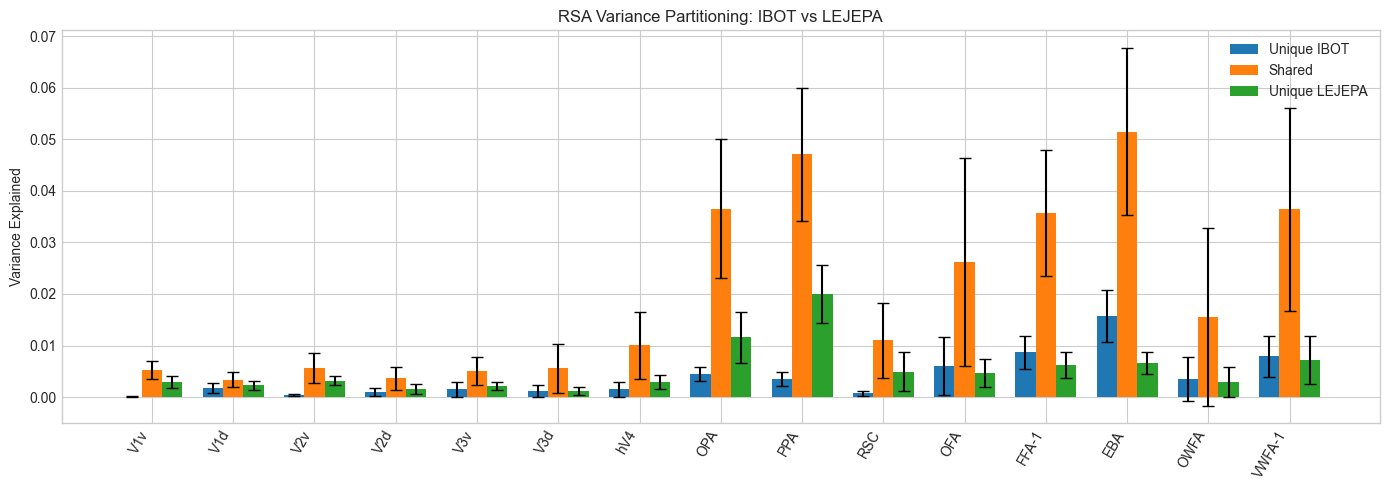

In [9]:
# ============================================================
# PLOT RSA UVP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

plot_df = results_df.copy()

# Remove "(0) " etc.
plot_df["ROI"] = plot_df["ROI"].astype(str).str.replace(
    "PATH", regex=True
)

# Extract actual ROI name
plot_df["ROI_base"] = plot_df["ROI"].str.extract(
    "PATH",
    expand=False
)

# Desired anatomical order
roi_order = [
    "V1v", "V1d",
    "V2v", "V2d",
    "V3v", "V3d",
    "hV4",
    "OPA", "PPA", "RSC",
    "OFA", "FFA-1", "EBA",
    "OWFA", "VWFA-1"
]

# Apply anatomical order
plot_df["ROI_base"] = pd.Categorical(
    plot_df["ROI_base"],
    categories=roi_order,
    ordered=True
)

plot_df = (
    plot_df
    .sort_values("ROI_base")
    .reset_index(drop=True)
)

# ============================================================
# CREATE BAR PLOT
# ============================================================

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(14, 5))

plt.bar(
    x - width,
    plot_df[f"Unique_{model1}"],
    width,
    yerr=plot_df[f"Unique_{model1}_STD"],
    capsize=4,
    label=f"Unique {model1}"
)

plt.bar(
    x,
    plot_df["Shared"],
    width,
    yerr=plot_df["Shared_STD"],
    capsize=4,
    label="Shared"
)

plt.bar(
    x + width,
    plot_df[f"Unique_{model2}"],
    width,
    yerr=plot_df[f"Unique_{model2}_STD"],
    capsize=4,
    label=f"Unique {model2}"
)

plt.xticks(
    x,
    plot_df["ROI_base"],
    rotation=60,
    ha="right"
)

plt.ylabel("Variance Explained")

plt.title(
    f"RSA Variance Partitioning: {model1} vs {model2}"
)

plt.legend()

plt.tight_layout()

plt.show()

# Linear Encoding and Ridge Regression

The toolbox offers `Linear Encoding` and `Ridge Regression` as evaluation metrics. These methods use raw features, without converting them into Representational Dissimilarity Matrices (RDMs), to train an encoding model that predicts unseen brain data.

* **Linear Encoding** uses Principal Component Analysis (PCA) followed by Linear Regression to reduce the feature dimensionality and then predict brain activity. It helps understand which features from the model correlate with brain responses.

* **Ridge Regression** extends linear encoding by adding regularization, which prevents overfitting and helps dealing with noise which may be part of the neural data.

### `Encoding` Function Parameters:

- **feat_path (str)**: Path to the directory with model activation `.npz` files for multiple layers.
- **roi_path (str or list)**: Path to the directory containing .npy fMRI data files for multiple ROIs.
If we have a list of folders, each folder will be searched for .npy files and the analysis will be run for each. If 
folders contain different subject ROIs, make sure that the .npy file names are unique (e.g. V1_subj1.npy) across the 
folders.
- **model_name (str)**: Name of the model (used for labeling in output files).
- **trn_tst_split (int or float)**: Data to use for training (rest is used for testing). If int, it is absolute 
number of samples, if float, it is a fraction of the whole dataset (e.g., 0.8 means 80% training, 20% testing).
- **n_folds (int)**: Number of cross-validation folds.
- **n_components (int)**: Number of principal components to retain during PCA (only linear encoding)
- **batch_size (int)**: Batch size for Incremental PCA. (only linear encoding)
- **srp_before_pca (bool)**: Whether to apply Sparse Random Projection (SRP) before PCA. Use when features are so
high-dimensional that IncrementalPCA runs out of memory after some batches. Num of dims estimated by SRP. (only linear encoding)
- **srp_on_subset (int or None)**: Number of samples to use for SRP fitting. If None, all samples are used,
which is recommended if you have enough memory (if `srp_before_pca` is False it has no effect). (only linear encoding)
- **mem_mode (str)**: 'saver' or 'performance'; Choose 'saver' if you don't have enough memory to store all
training sample features, otherwise leave 'performance' as default. If you have `srp_before_pca` enabled,
in the first case you will also need to restrict the number of samples for SRP fitting with `srp_on_subset`. (only linear encoding)
- **pooling (str or None)**: Pooling method for variable-length features. Options: 'mean', 'max', 'first', 'last'. Required when features have variable lengths (e.g., LLM token sequences). Use 'mean' for average pooling, 'max' for max pooling, 'first' for taking the first token/position (like [CLS] token), 'last' for taking the final token/position. If None, features are flattened (only works with fixed-length features).
- **return_correlations (bool)**: If True, return correlation values for each voxel (only with veRSA False).
- **random_state (int)**: Seed for reproducibility of results.
- **shuffle (bool)**: Whether to shuffle the data before splitting into training and testing sets.
- **save_path (str)**: Directory to save results (`Linear_Encoding_Results` by default).
- **file_name (str or None)**: Custom file name for saved results.
- **average_across_layers (bool)**: If True, averages correlation values across layers before saving the results.
- **veRSA (bool)**: If True, performs RSA on top of the voxelwise encoding.
- **save_model (bool)**: Save the linear regression model to disk.
- **save_pca (bool)**: Save the PCA transform to disk.
- **layer_skips (tuple, optional)**: Names of the model layers to skip during encoding. Use original layer names.


In [ ]:

# For a proper tutorial check out "notebooks/Workshops/Cognition Academy Dresden Notebook 2.ipynb"

from net2brain.evaluations.encoding import Linear_Encoding, Ridge_Encoding

Linear_Encoding(feat_path="feat_path",  
                roi_path="roi_path",
                model_name="model_name",
                save_path="save_path",
                file_name="file_name",
                avg_across_feat=True,
                return_correlations=False,
                average_across_layers=False)


Ridge_Encoding(feat_path="feat_path", 
                roi_path="roi_path",
                model_name="model_name",
                save_path="save_path",
                file_name="file_name",
                avg_across_feat=True,
                return_correlations=False,
                average_across_layers=False)

In [5]:
# combine l+r
import os
import numpy as np

# Output folder
output_root = "PATH"
os.makedirs(output_root, exist_ok=True)

# -------------------------
# Find ROIs present in all subjects
# -------------------------

valid_rois = []

subj01_files = os.listdir(paths_NSD_shared["subj01_rois"])

candidate_rois = sorted({
    f.split("_lh_")[0]
    for f in subj01_files
    if "_lh_" in f
})

for roi in candidate_rois:
    valid = True

    for subj in range(1, 9):
        subj_str = f"subj0{subj}"

        lh_path = os.path.join(
            paths_NSD_shared[f"{subj_str}_rois"],
            f"{roi}_lh_{subj_str}.npy"
        )

        rh_path = os.path.join(
            paths_NSD_shared[f"{subj_str}_rois"],
            f"{roi}_rh_{subj_str}.npy"
        )

        if not (os.path.exists(lh_path) and os.path.exists(rh_path)):
            valid = False
            break

    if valid:
        valid_rois.append(roi)

print("ROIs:", valid_rois)

# -------------------------
# Combine hemispheres
# -------------------------

for subj in range(1, 9):

    subj_str = f"subj0{subj}"
    save_dir = os.path.join(output_root, subj_str)
    os.makedirs(save_dir, exist_ok=True)

    print(f"\nProcessing {subj_str}")

    for roi in valid_rois:

        lh = np.load(os.path.join(
            paths_NSD_shared[f"{subj_str}_rois"],
            f"{roi}_lh_{subj_str}.npy"
        ))

        rh = np.load(os.path.join(
            paths_NSD_shared[f"{subj_str}_rois"],
            f"{roi}_rh_{subj_str}.npy"
        ))

        combined = np.concatenate([lh, rh], axis=1)

        np.save(
            os.path.join(save_dir, f"{roi}_combined_{subj_str}.npy"),
            combined
        )

print("\nDone!")

ROIs: ['EBA', 'FFA-1', 'OFA', 'OPA', 'OWFA', 'PPA', 'RSC', 'V1d', 'V1v', 'V2d', 'V2v', 'V3d', 'V3v', 'VWFA-1', 'hV4']

Processing subj01

Processing subj02

Processing subj03

Processing subj04

Processing subj05

Processing subj06

Processing subj07

Processing subj08

Done!


In [21]:
from net2brain.evaluations.encoding import Linear_Encoding
import os

combined_root = "PATH"

for subject in range(1, 9):
    roi_path = os.path.join(combined_root, f"subj{subject:02d}")

    Linear_Encoding(
        feat_path="PATH",
        roi_path=roi_path,
        model_name="OPENCLIP_cls",
        save_path=f"PATH",
        file_name=f"openclip_encoding_combined_cls_subj{subject:02d}",
        pooling="mean",
        return_correlations=True,
        average_across_layers=False,
        n_components=100,
        batch_size=872
    )
print('done')

Using pooling method 'mean' for variable-length features. This will mean pool activations across the sequence dimension.


C:\Users\louai\net2brain-env\lib\site-packages\net2brain\evaluations\eval_helper.py:151: UserWarning: Ignoring folders in the list.
  warnings.warn("Ignoring folders in the list.")
Fold 2: 100%|████████████████████████████████████████████| 12/12 [04:11<00:00, 21.00s/it, Layer=layer_12, ROIs=15 ROIs]
C:\Users\louai\net2brain-env\lib\site-packages\net2brain\evaluations\eval_helper.py:151: UserWarning: Ignoring folders in the list.
  warnings.warn("Ignoring folders in the list.")


Using pooling method 'mean' for variable-length features. This will mean pool activations across the sequence dimension.


Fold 2: 100%|████████████████████████████████████████████| 12/12 [03:44<00:00, 18.72s/it, Layer=layer_12, ROIs=15 ROIs]
C:\Users\louai\net2brain-env\lib\site-packages\net2brain\evaluations\eval_helper.py:151: UserWarning: Ignoring folders in the list.
  warnings.warn("Ignoring folders in the list.")


Using pooling method 'mean' for variable-length features. This will mean pool activations across the sequence dimension.


...

Using pooling method 'mean' for variable-length features. This will mean pool activations across the sequence dimension.


Fold 2: 100%|████████████████████████████████████████████| 12/12 [04:47<00:00, 24.00s/it, Layer=layer_12, ROIs=15 ROIs]
C:\Users\louai\net2brain-env\lib\site-packages\net2brain\evaluations\eval_helper.py:151: UserWarning: Ignoring folders in the list.
  warnings.warn("Ignoring folders in the list.")


Using pooling method 'mean' for variable-length features. This will mean pool activations across the sequence dimension.


Fold 2: 100%|████████████████████████████████████████████| 12/12 [05:04<00:00, 25.37s/it, Layer=layer_12, ROIs=15 ROIs]


done


In [ ]:
Ridge_Encoding(feat_path="feat_path", 
                roi_path="roi_path",
                model_name="model_name",
                save_path="save_path",
                file_name="file_name",
                avg_across_feat=True,
                return_correlations=False,
                average_across_layers=False)

## visualization

In [18]:
import inspect
from net2brain.evaluations.plotting import Plotting

print(inspect.getfile(Plotting))

C:\Users\louai\net2brain-env\lib\site-packages\net2brain\evaluations\plotting.py


### all model groups + all subjects


GROUP: vitl

Subject 01
  LeJEPA: lejepa_encoding_combined_lukas_subj01.csv
  MAE: mae_encoding_combined_cls_subj01.csv
  iBOT: ibot_encoding_combined_an_cls_subj01.csv


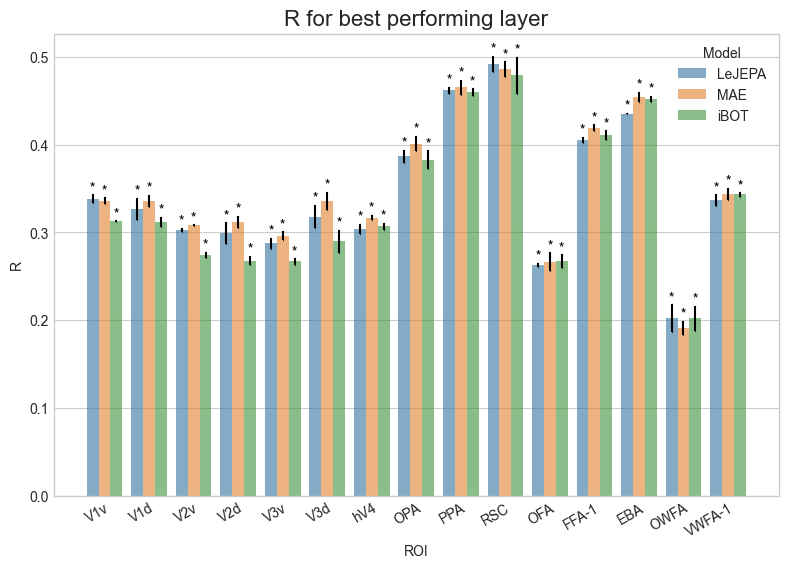

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitl_LE_subj01.png

Subject 02
  LeJEPA: lejepa_encoding_combined_lukas_subj02.csv
  MAE: mae_encoding_combined_cls_subj02.csv
  iBOT: ibot_encoding_combined_an_cls_subj02.csv


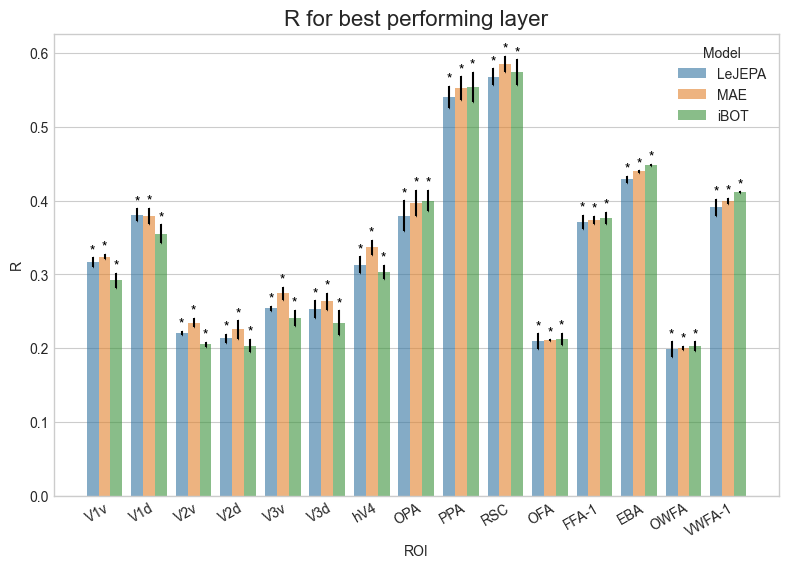

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitl_LE_subj02.png

Subject 03
  LeJEPA: lejepa_encoding_combined_lukas_subj03.csv
  MAE: mae_encoding_combined_cls_subj03.csv
  iBOT: ibot_encoding_combined_an_cls_subj03.csv


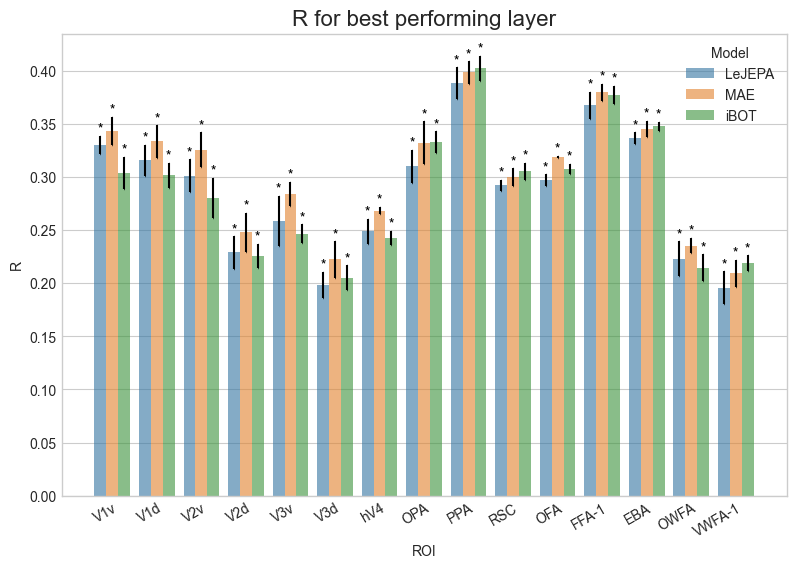

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitl_LE_subj03.png

Subject 04
  LeJEPA: lejepa_encoding_combined_lukas_subj04.csv
  MAE: mae_encoding_combined_cls_subj04.csv
  iBOT: ibot_encoding_combined_an_cls_subj04.csv


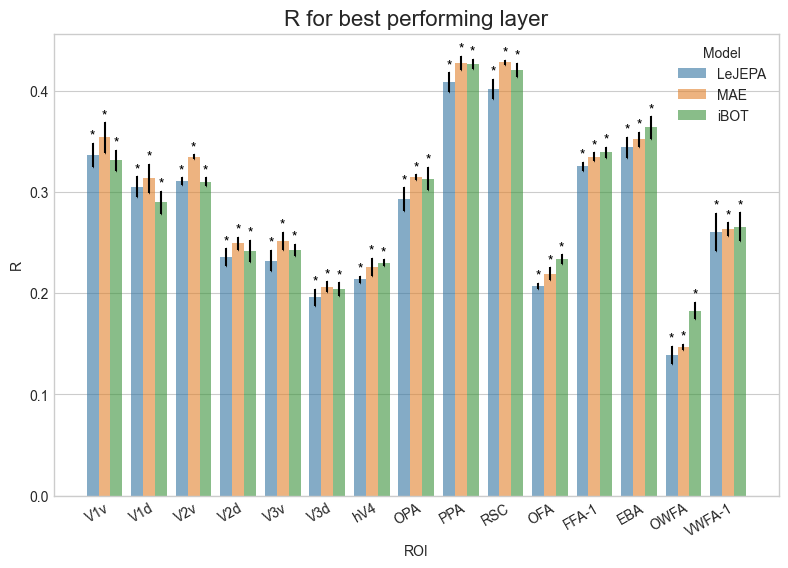

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitl_LE_subj04.png

Subject 05
  LeJEPA: lejepa_encoding_combined_lukas_subj05.csv
  MAE: mae_encoding_combined_cls_subj05.csv
  iBOT: ibot_encoding_combined_an_cls_subj05.csv


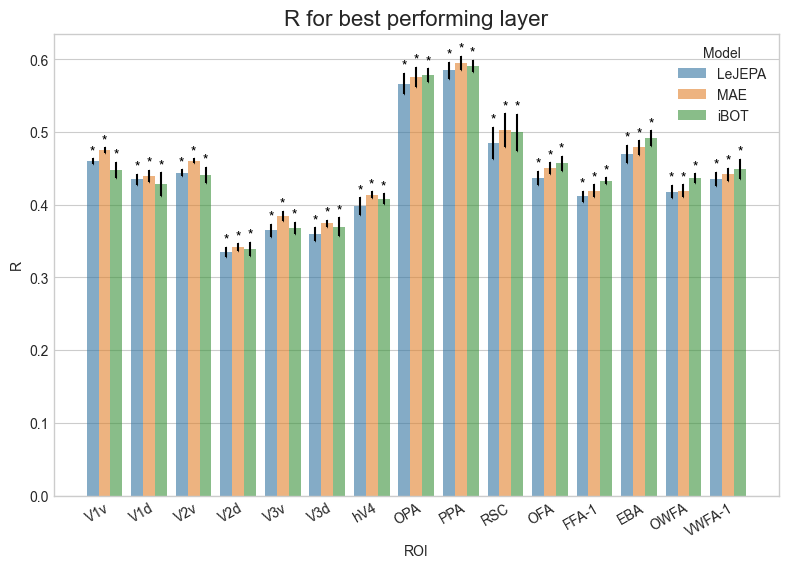

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitl_LE_subj05.png

Subject 06
  LeJEPA: lejepa_encoding_combined_lukas_subj06.csv
  MAE: mae_encoding_combined_cls_subj06.csv
  iBOT: ibot_encoding_combined_an_cls_subj06.csv


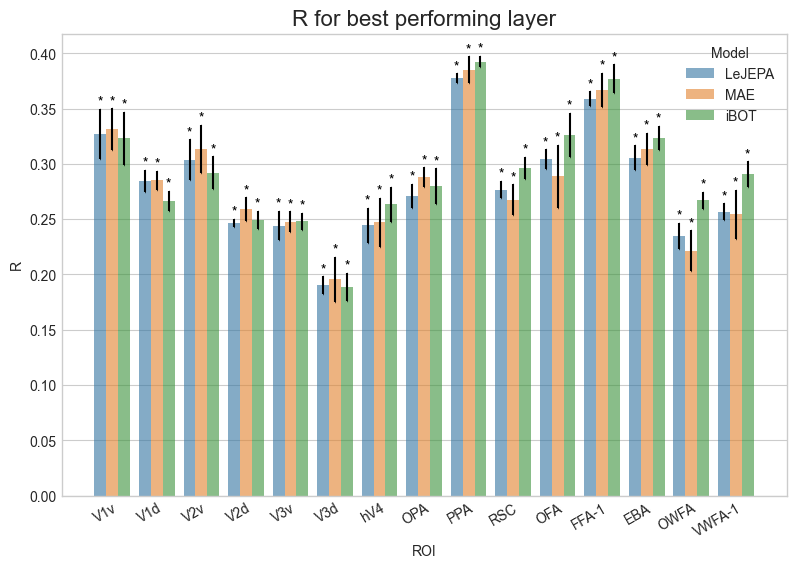

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitl_LE_subj06.png

Subject 07
  LeJEPA: lejepa_encoding_combined_lukas_subj07.csv
  MAE: mae_encoding_combined_cls_subj07.csv
  iBOT: ibot_encoding_combined_an_cls_subj07.csv


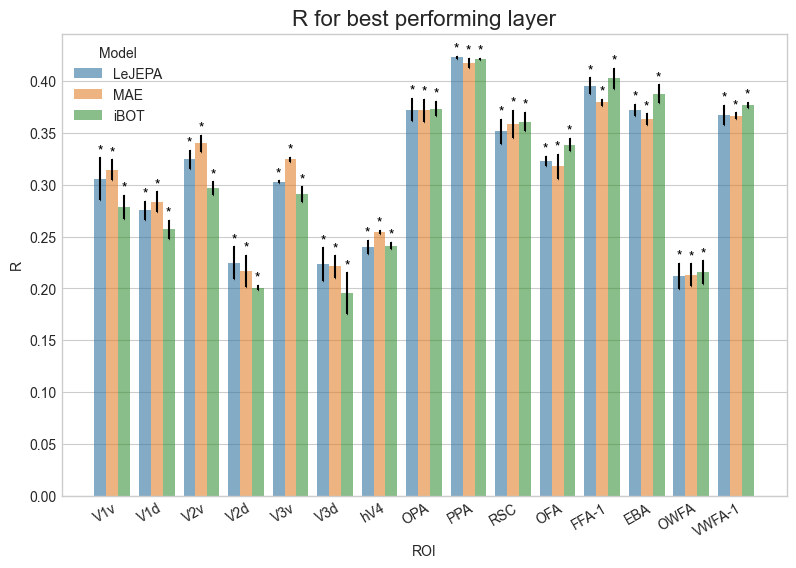

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitl_LE_subj07.png

Subject 08
  LeJEPA: lejepa_encoding_combined_lukas_subj08.csv
  MAE: mae_encoding_combined_cls_subj08.csv
  iBOT: ibot_encoding_combined_an_cls_subj08.csv


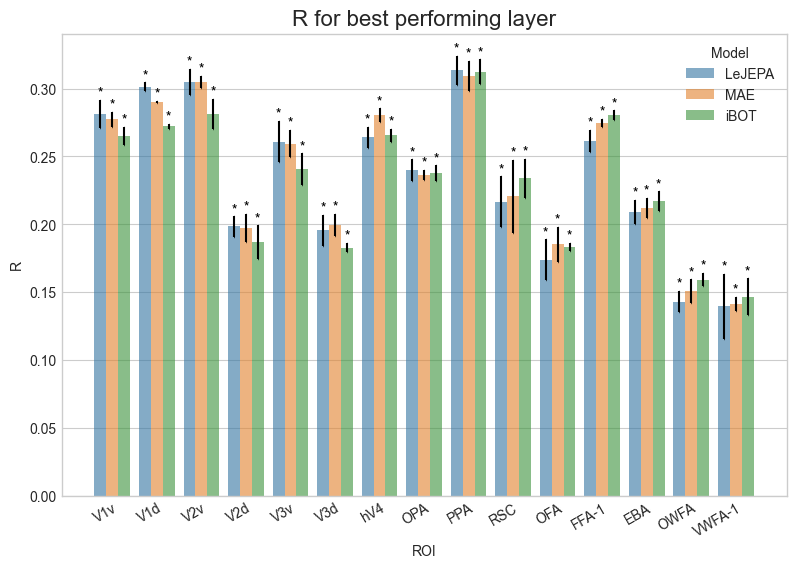

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitl_LE_subj08.png

GROUP: vitb

Subject 01
  LeJEPA: lejepa_encoding_lukas_vitb_combined_subj01.csv
  DINOv1: dinov1_encoding_combined_an_cls_subj01.csv


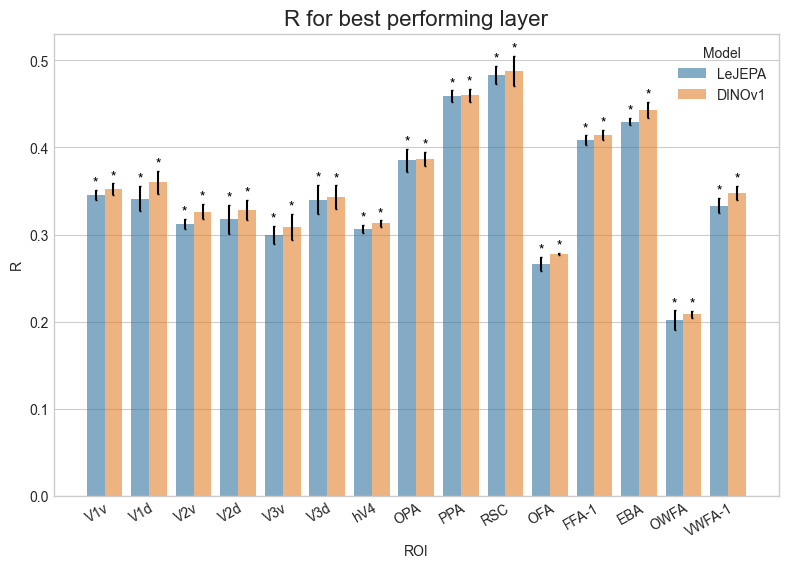

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitb_LE_subj01.png

Subject 02
  LeJEPA: lejepa_encoding_lukas_vitb_combined_subj02.csv
  DINOv1: dinov1_encoding_combined_an_cls_subj02.csv


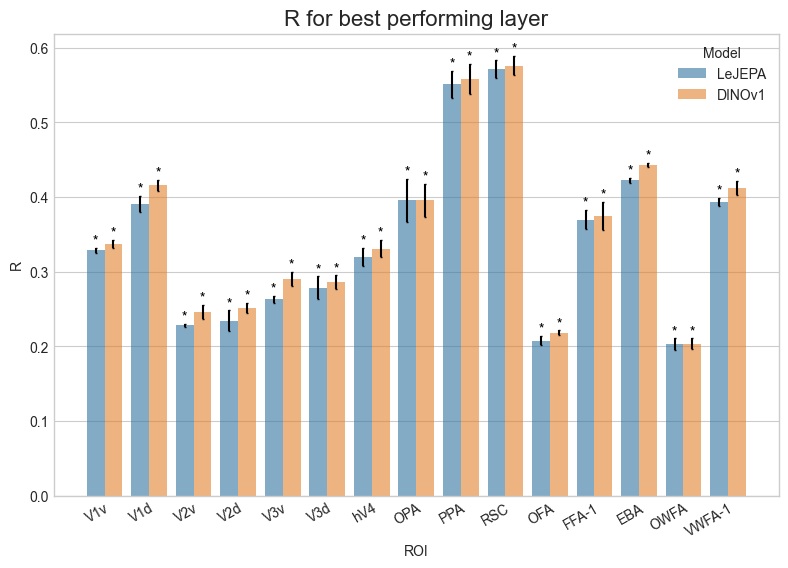

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitb_LE_subj02.png

Subject 03
  LeJEPA: lejepa_encoding_lukas_vitb_combined_subj03.csv
  DINOv1: dinov1_encoding_combined_an_cls_subj03.csv


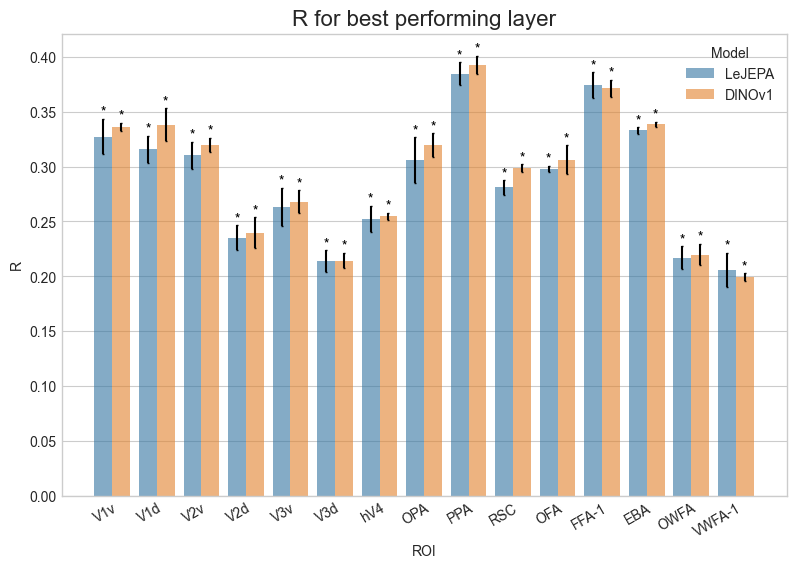

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitb_LE_subj03.png

Subject 04
  LeJEPA: lejepa_encoding_lukas_vitb_combined_subj04.csv
  DINOv1: dinov1_encoding_combined_an_cls_subj04.csv


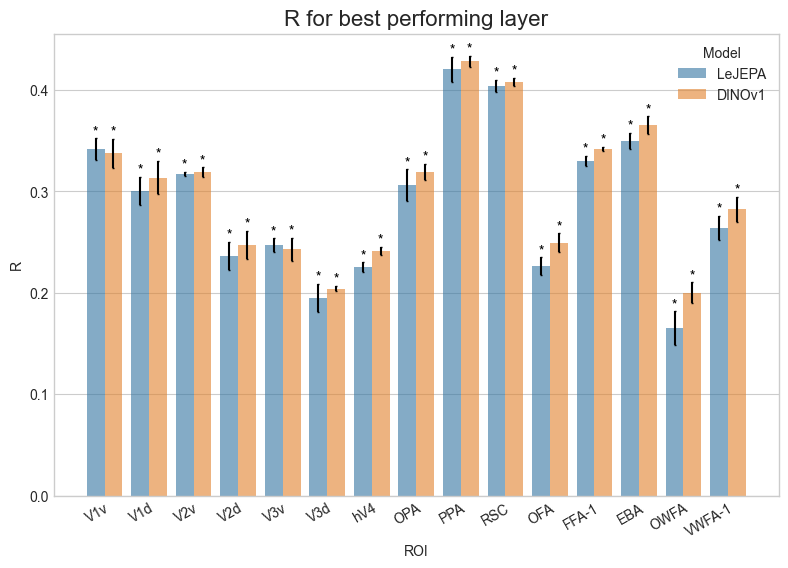

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitb_LE_subj04.png

Subject 05
  LeJEPA: lejepa_encoding_lukas_vitb_combined_subj05.csv
  DINOv1: dinov1_encoding_combined_an_cls_subj05.csv


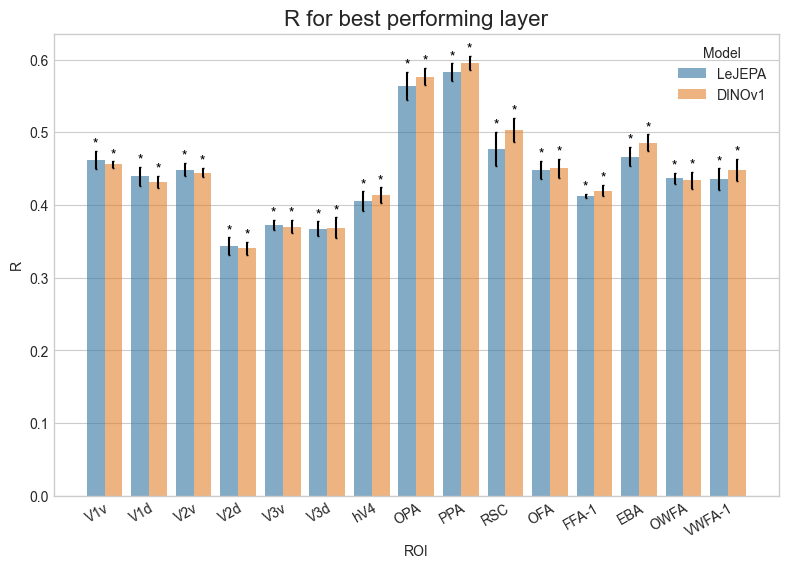

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitb_LE_subj05.png

Subject 06
  LeJEPA: lejepa_encoding_lukas_vitb_combined_subj06.csv
  DINOv1: dinov1_encoding_combined_an_cls_subj06.csv


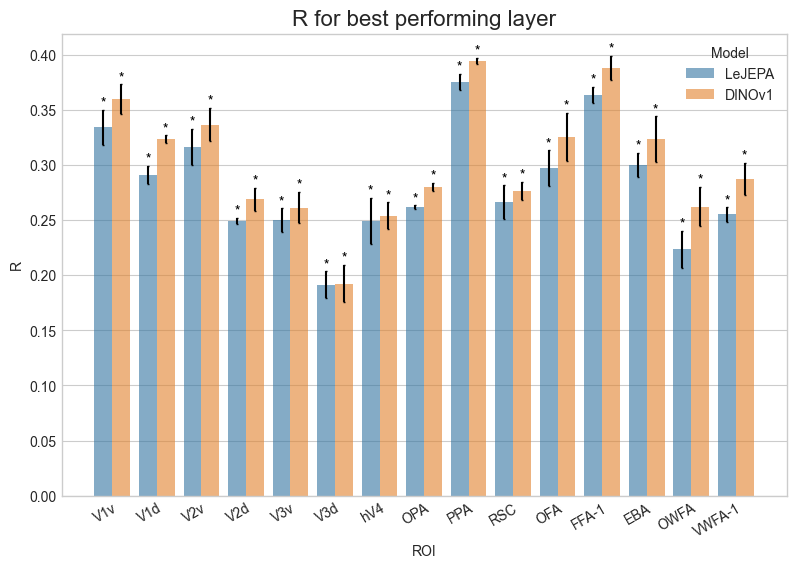

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitb_LE_subj06.png

Subject 07
  LeJEPA: lejepa_encoding_lukas_vitb_combined_subj07.csv
  DINOv1: dinov1_encoding_combined_an_cls_subj07.csv


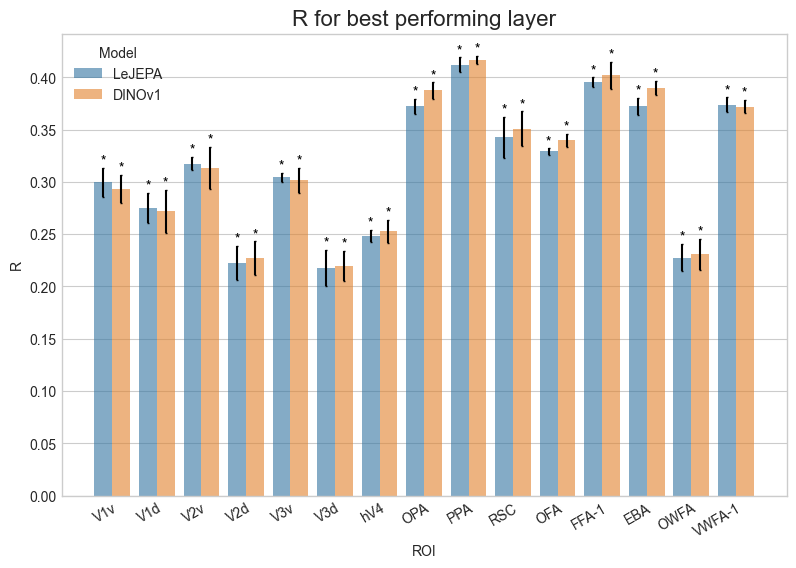

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitb_LE_subj07.png

Subject 08
  LeJEPA: lejepa_encoding_lukas_vitb_combined_subj08.csv
  DINOv1: dinov1_encoding_combined_an_cls_subj08.csv


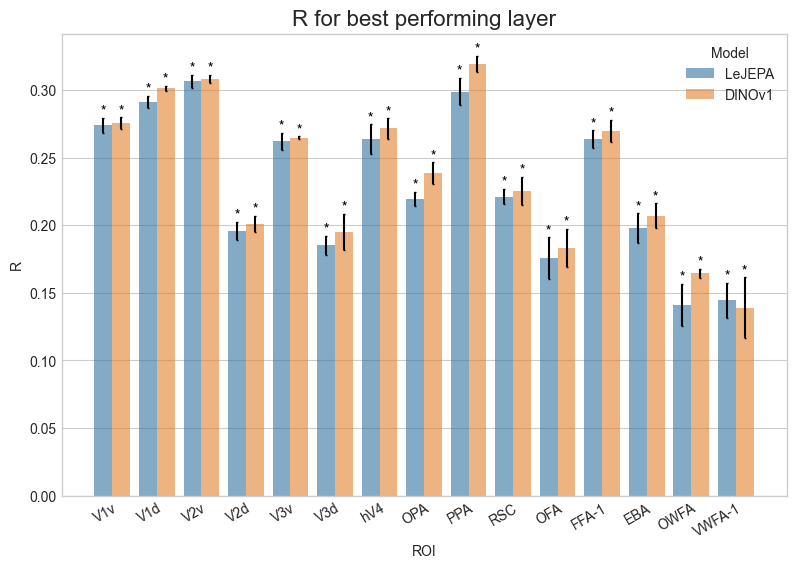

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vitb_LE_subj08.png

GROUP: vl

Subject 01
  LeVLJEPA: vljepa_encoding_combined_subj01.csv


FileNotFoundError: No CSV found in:
C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\clip_combined\subj01

In [5]:
import os
import glob
import pandas as pd
from net2brain.evaluations.plotting import Plotting


# ============================================================
# "PATH"S
# ============================================================

results_root = "PATH"

output_root = os.path.join(
    results_root,
    "LE_plots"
)

os.makedirs(output_root, exist_ok=True)


# ============================================================
# MODEL GROUPS
# ============================================================
#
# Order matters:
# JEPA models are placed first so they consistently receive
# the first color in their respective plots.
#
# ============================================================

model_groups = {

    # --------------------------------------------------------
    # Image models - ViT-L
    # --------------------------------------------------------
    "vitl": [
        ("lejepa_combined_lukas", "LeJEPA"),
        ("mae_combined_cls", "MAE"),
        ("ibot_combined_an_cls", "iBOT"),
    ],

    # --------------------------------------------------------
    # Image models - ViT-B
    # --------------------------------------------------------
    "vitb": [
        ("lejepa_lukas_vitb_combined", "LeJEPA"),
        ("dinov1_combined_an_cls", "DINOv1"),
    ],

    # --------------------------------------------------------
    # Vision-language models
    # --------------------------------------------------------
    "vl": [
        ("vljepa_combined", "LeVLJEPA"),
        ("infonce_combined", "InfoNCE"),
        ("openclip_combined_cls", "OpenCLIP"),
    ],

    # --------------------------------------------------------
    # Video models
    # --------------------------------------------------------
    "video": [
        ("levjepa_combined", "LeVJEPA"),
        ("vjepa_combined", "VJEPA"),
        ("videomae_combined", "VideoMAE"),
        ("dinov2_video_combined", "DINOv2"),
    ],
}


# ============================================================
# ANATOMICAL ROI ORDER
# ============================================================

roi_order = [
    "V1v", "V1d",
    "V2v", "V2d",
    "V3v", "V3d",
    "hV4",
    "OPA", "PPA", "RSC",
    "OFA", "FFA-1", "EBA",
    "OWFA", "VWFA-1",
]


# ============================================================
# FIND CSV
# ============================================================

def find_subject_csv(model_folder, subject):

    subject_folder = os.path.join(
        results_root,
        model_folder,
        f"subj{subject:02d}"
    )

    csv_files = glob.glob(
        os.path.join(subject_folder, "*.csv")
    )

    if len(csv_files) == 0:
        raise FileNotFoundError(
            f"No CSV found in:\n{subject_folder}"
        )

    if len(csv_files) > 1:
        raise RuntimeError(
            f"Multiple CSV files found in:\n"
            f"{subject_folder}\n\n"
            f"{csv_files}"
        )

    return csv_files[0]


# ============================================================
# GENERATE PLOTS
# ============================================================

for group_name, models in model_groups.items():

    print("\n" + "=" * 70)
    print(f"GROUP: {group_name}")
    print("=" * 70)

    for subject in range(1, 9):

        print(f"\nSubject {subject:02d}")

        dataframes = []
        model_names = []

        # ----------------------------------------------------
        # LOAD MODELS
        # ----------------------------------------------------

        for model_folder, model_display_name in models:

            csv_path = find_subject_csv(
                model_folder,
                subject
            )

            print(
                f"  {model_display_name}: "
                f"{os.path.basename(csv_path)}"
            )

            dataframe = pd.read_csv(csv_path)

            # ------------------------------------------------
            # CLEAN ROI NAMES
            #
            # Example:
            # EBA_combined_subj01
            #        ↓
            # EBA
            #
            # FFA-1_combined_subj01
            #        ↓
            # FFA-1
            # ------------------------------------------------

            dataframe["ROI"] = (
                dataframe["ROI"]
                .astype(str)
                .str.replace(
                    "PATH",
                    "",
                    regex=True
                )
            )

            dataframes.append(dataframe)
            model_names.append(model_display_name)

        # ----------------------------------------------------
        # CREATE PLOTTER
        # ----------------------------------------------------

        plotter = Plotting(dataframes)

        # ----------------------------------------------------
        # OUTPUT "PATH"
        # ----------------------------------------------------

        output_path = os.path.join(
            output_root,
            f"{group_name}_LE_subj{subject:02d}.png"
        )

        # ----------------------------------------------------
        # GENERATE PLOT
        # ----------------------------------------------------

        results_dataframe = plotter.plot(
            metric="R",
            save_path=output_path,
            model_names=model_names
        )

        print(f"  -> Saved: {output_path}")


print("\n" + "=" * 70)
print("ALL LINEAR-ENCODING PLOTS GENERATED")
print("=" * 70)


GROUP: vl

Subject 01
  LeVLJEPA: vljepa_encoding_combined_subj01.csv
  InfoNCE: infonce_encoding_combined_subj01.csv
  OpenCLIP: openclip_encoding_combined_cls_subj01.csv


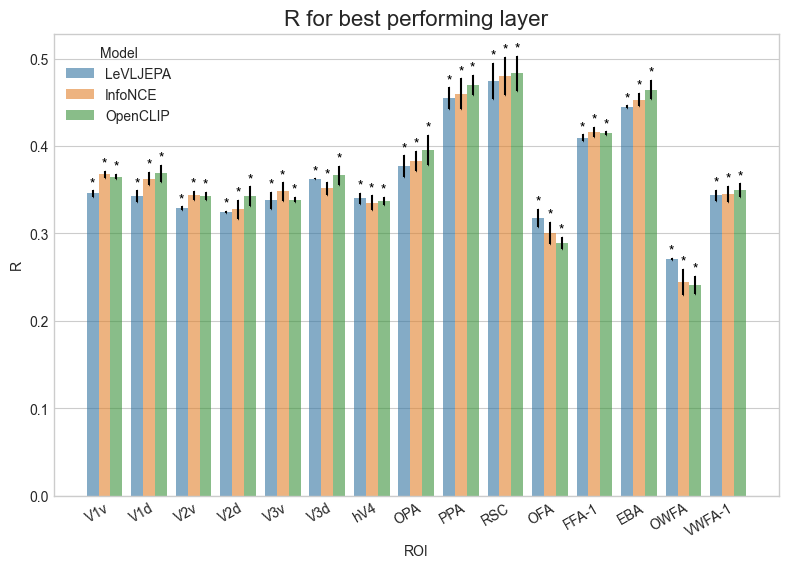

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vl_LE_subj01.png

Subject 02
  LeVLJEPA: vljepa_encoding_combined_subj02.csv
  InfoNCE: infonce_encoding_combined_subj02.csv
  OpenCLIP: openclip_encoding_combined_cls_subj02.csv


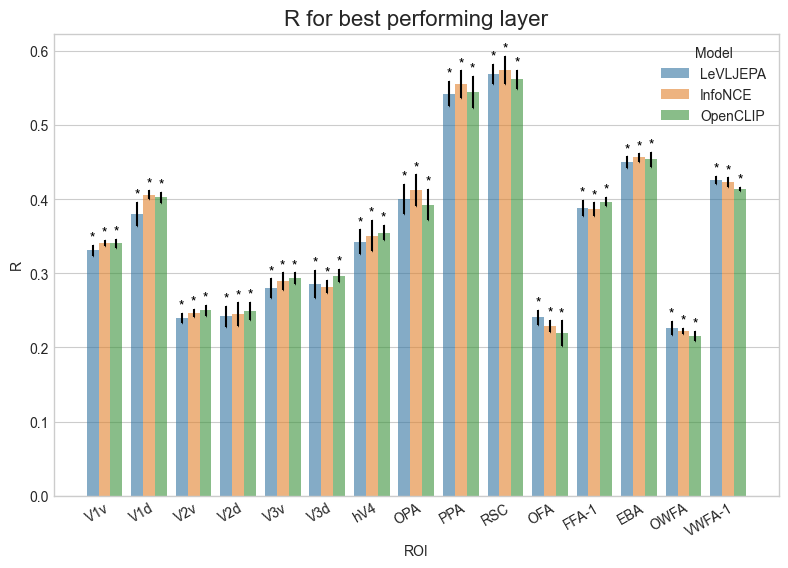

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vl_LE_subj02.png

Subject 03
  LeVLJEPA: vljepa_encoding_combined_subj03.csv
  InfoNCE: infonce_encoding_combined_subj03.csv
  OpenCLIP: openclip_encoding_combined_cls_subj03.csv


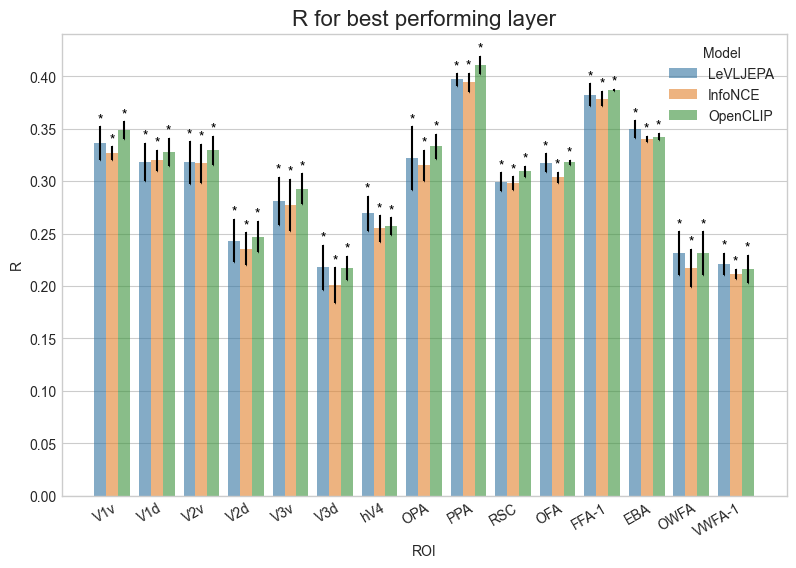

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vl_LE_subj03.png

Subject 04
  LeVLJEPA: vljepa_encoding_combined_subj04.csv
  InfoNCE: infonce_encoding_combined_subj04.csv
  OpenCLIP: openclip_encoding_combined_cls_subj04.csv


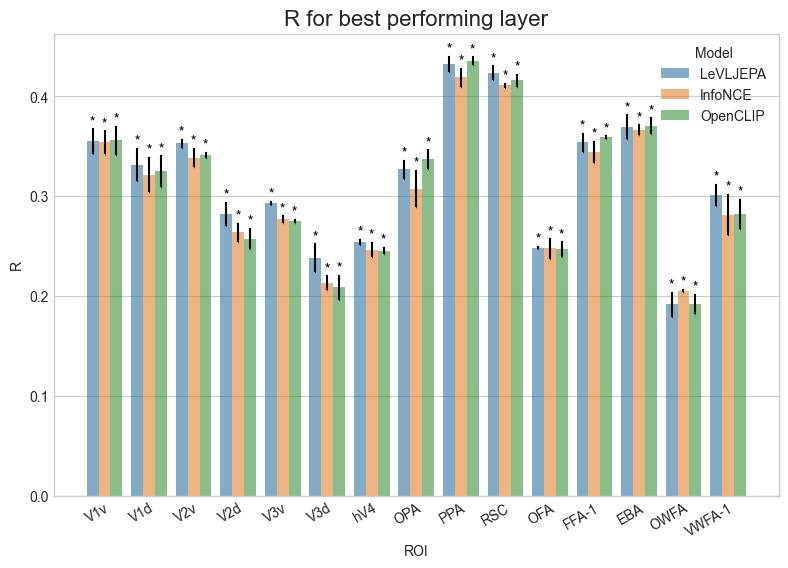

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vl_LE_subj04.png

Subject 05
  LeVLJEPA: vljepa_encoding_combined_subj05.csv
  InfoNCE: infonce_encoding_combined_subj05.csv
  OpenCLIP: openclip_encoding_combined_cls_subj05.csv


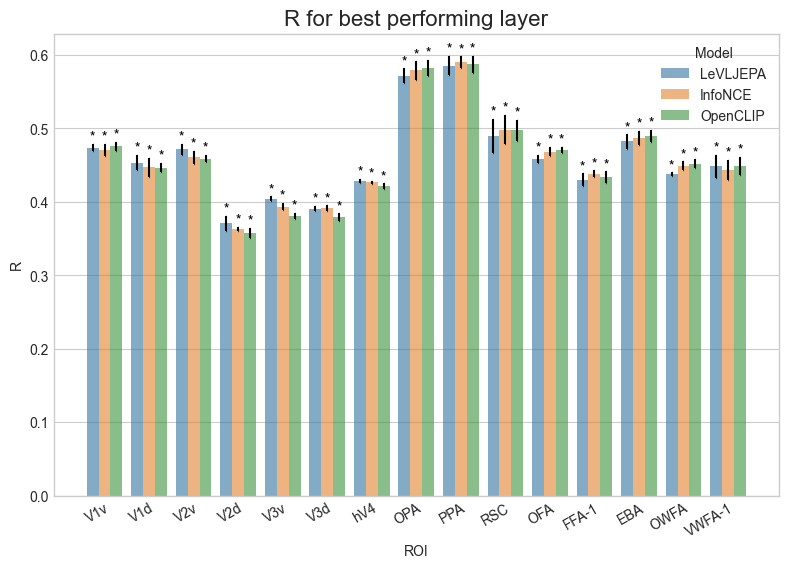

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vl_LE_subj05.png

Subject 06
  LeVLJEPA: vljepa_encoding_combined_subj06.csv
  InfoNCE: infonce_encoding_combined_subj06.csv
  OpenCLIP: openclip_encoding_combined_cls_subj06.csv


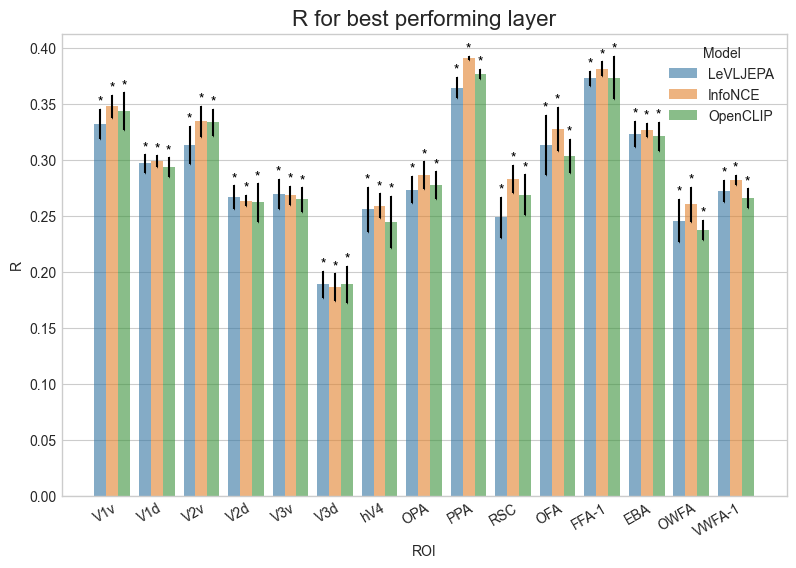

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vl_LE_subj06.png

Subject 07
  LeVLJEPA: vljepa_encoding_combined_subj07.csv
  InfoNCE: infonce_encoding_combined_subj07.csv
  OpenCLIP: openclip_encoding_combined_cls_subj07.csv


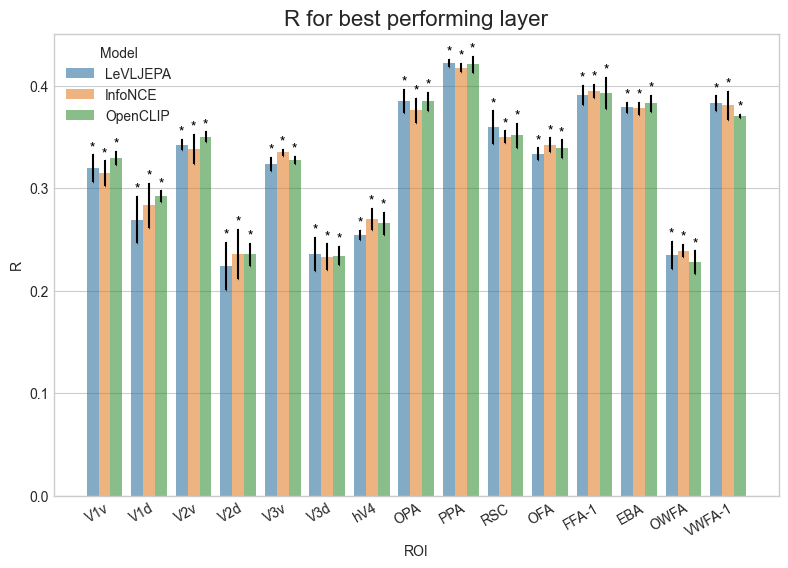

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vl_LE_subj07.png

Subject 08
  LeVLJEPA: vljepa_encoding_combined_subj08.csv
  InfoNCE: infonce_encoding_combined_subj08.csv
  OpenCLIP: openclip_encoding_combined_cls_subj08.csv


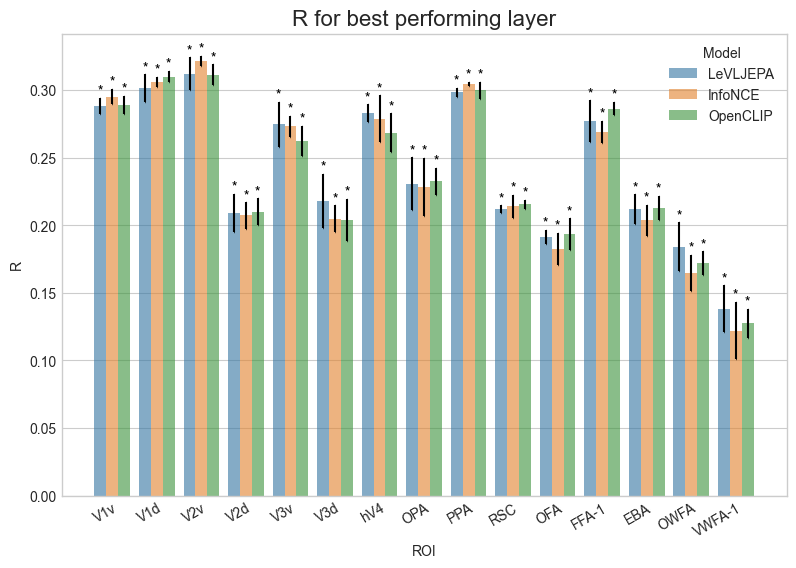

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\vl_LE_subj08.png

GROUP: video

Subject 01
  LeVJEPA: levjepa_encoding_combined_subj01.csv
  VJEPA: vjepa_encoding_combined_subj01.csv
  VideoMAE: videomae_encoding_combined_subj01.csv
  DINOv2: dinov2_video_encoding_combined_subj01.csv


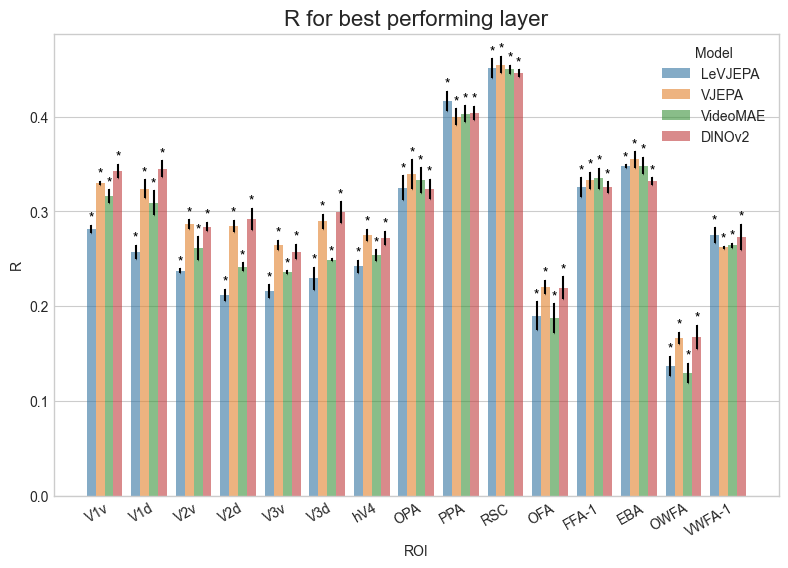

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\video_LE_subj01.png

Subject 02
  LeVJEPA: levjepa_encoding_combined_subj02.csv
  VJEPA: vjepa_encoding_combined_subj02.csv
  VideoMAE: videomae_encoding_combined_subj02.csv
  DINOv2: dinov2_video_encoding_combined_subj02.csv


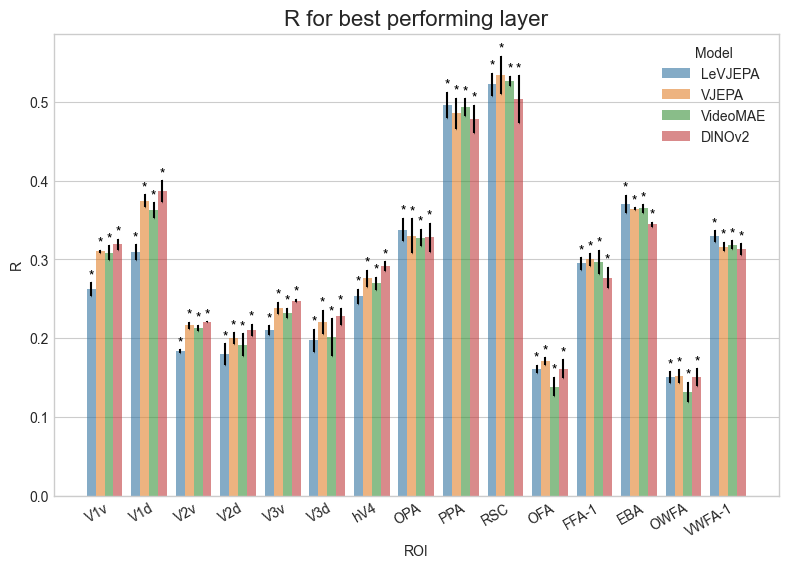

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\video_LE_subj02.png

Subject 03
  LeVJEPA: levjepa_encoding_combined_subj03.csv
  VJEPA: vjepa_encoding_combined_subj03.csv
  VideoMAE: videomae_encoding_combined_subj03.csv
  DINOv2: dinov2_video_encoding_combined_subj03.csv


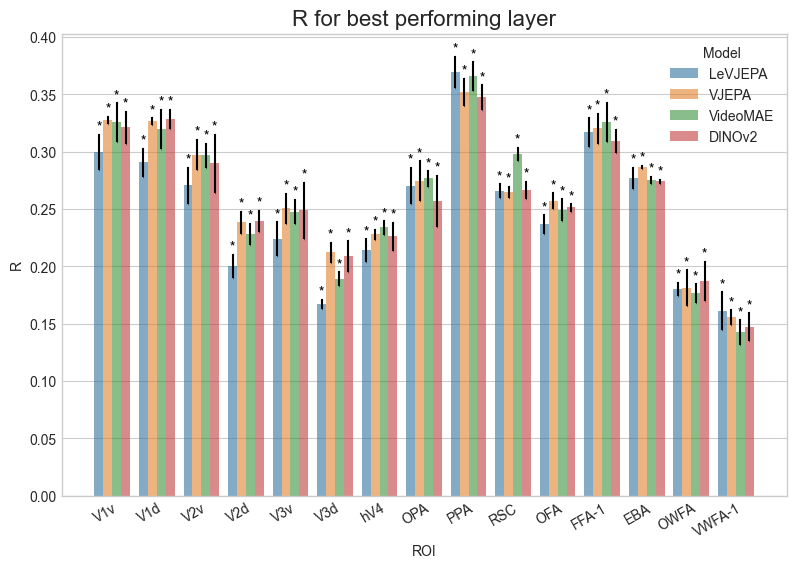

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\video_LE_subj03.png

Subject 04
  LeVJEPA: levjepa_encoding_combined_subj04.csv
  VJEPA: vjepa_encoding_combined_subj04.csv
  VideoMAE: videomae_encoding_combined_subj04.csv
  DINOv2: dinov2_video_encoding_combined_subj04.csv


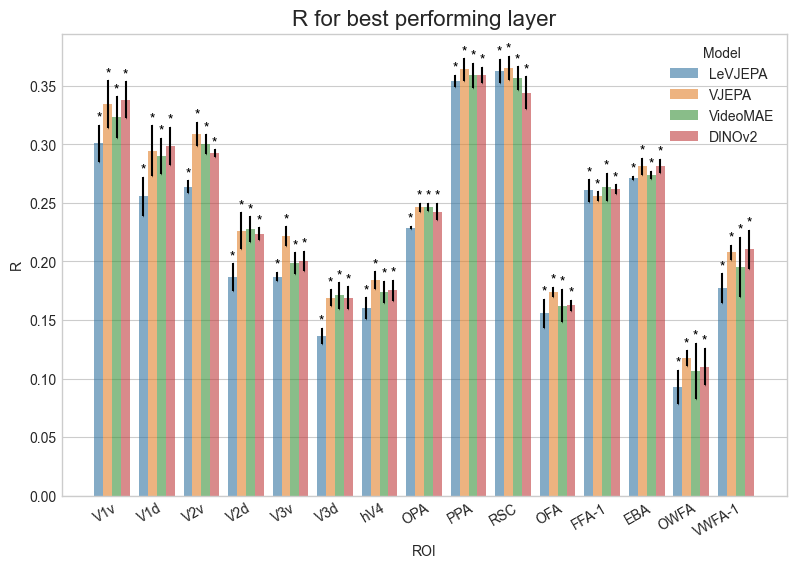

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\video_LE_subj04.png

Subject 05
  LeVJEPA: levjepa_encoding_combined_subj05.csv
  VJEPA: vjepa_encoding_combined_subj05.csv
  VideoMAE: videomae_encoding_combined_subj05.csv
  DINOv2: dinov2_video_encoding_combined_subj05.csv


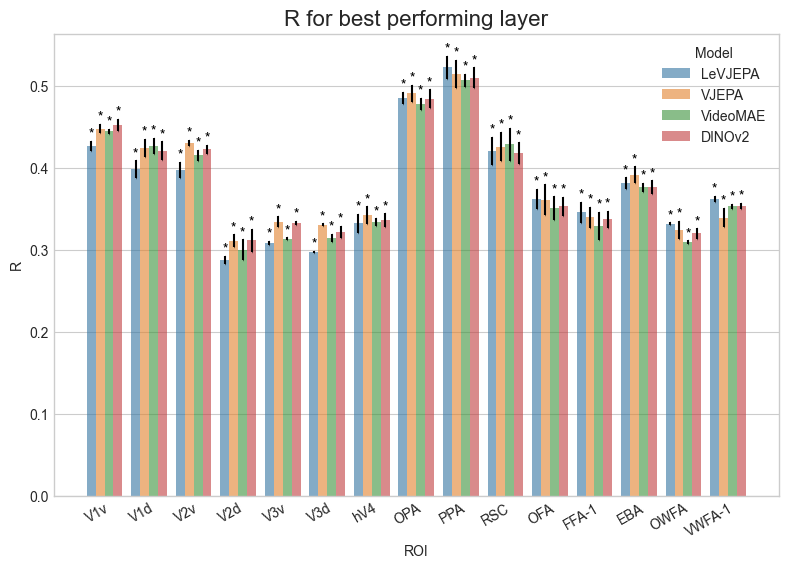

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\video_LE_subj05.png

Subject 06
  LeVJEPA: levjepa_encoding_combined_subj06.csv
  VJEPA: vjepa_encoding_combined_subj06.csv
  VideoMAE: videomae_encoding_combined_subj06.csv
  DINOv2: dinov2_video_encoding_combined_subj06.csv


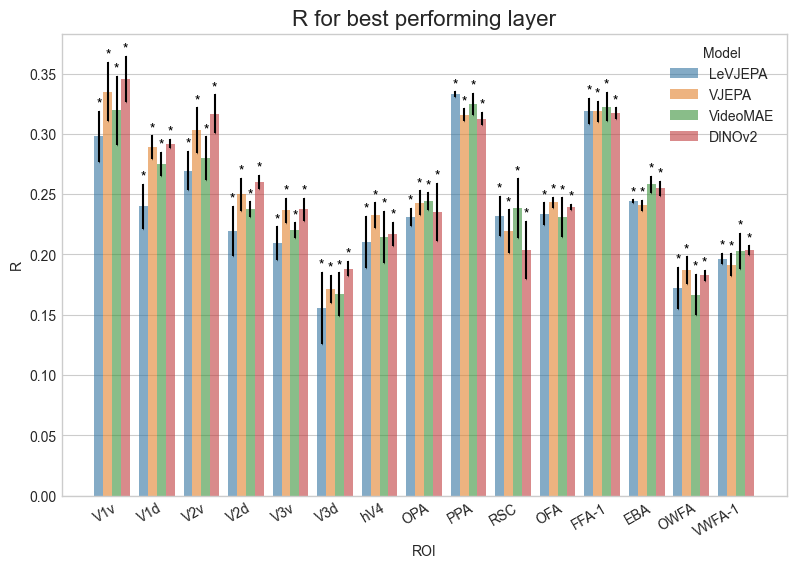

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\video_LE_subj06.png

Subject 07
  LeVJEPA: levjepa_encoding_combined_subj07.csv
  VJEPA: vjepa_encoding_combined_subj07.csv
  VideoMAE: videomae_encoding_combined_subj07.csv
  DINOv2: dinov2_video_encoding_combined_subj07.csv


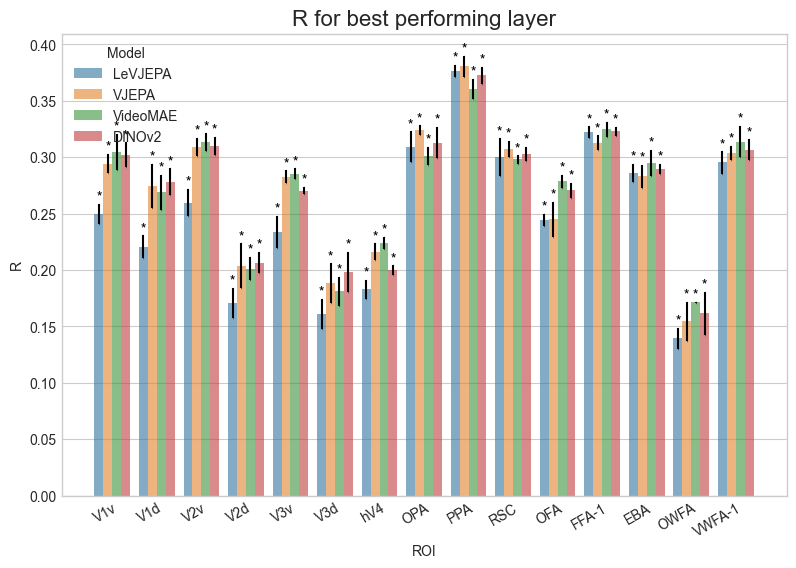

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\video_LE_subj07.png

Subject 08
  LeVJEPA: levjepa_encoding_combined_subj08.csv
  VJEPA: vjepa_encoding_combined_subj08.csv
  VideoMAE: videomae_encoding_combined_subj08.csv
  DINOv2: dinov2_video_encoding_combined_subj08.csv


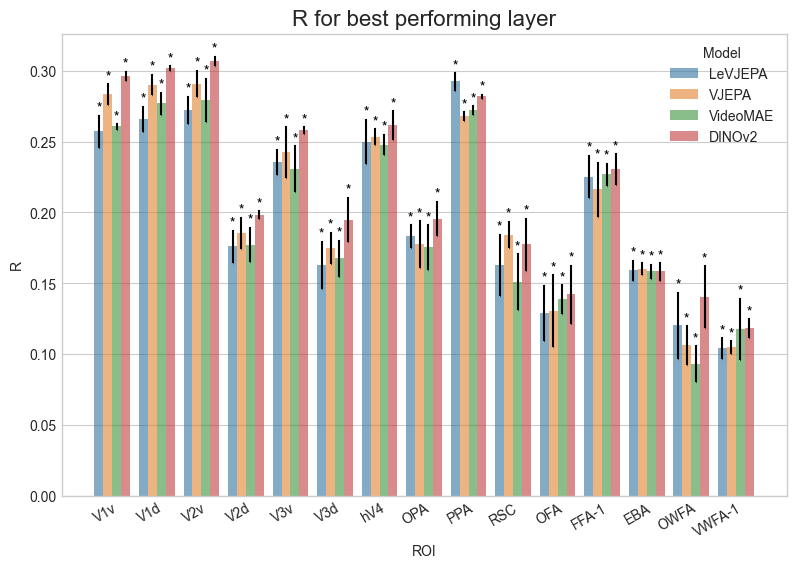

  -> Saved: C:\Users\louai\Net2Brain\notebooks\0_encoding_results\_correct\LE_plots\video_LE_subj08.png

VISION-LANGUAGE AND VIDEO PLOTS GENERATED


In [8]:
import os
import glob
import pandas as pd
from net2brain.evaluations.plotting import Plotting


# ============================================================
# "PATH"S
# ============================================================

results_root = "PATH"

output_root = os.path.join(
    results_root,
    "LE_plots"
)

os.makedirs(output_root, exist_ok=True)


# ============================================================
# MODEL GROUPS
# ============================================================

model_groups = {

    # --------------------------------------------------------
    # Vision-Language models
    # --------------------------------------------------------

    "vl": [
        ("vljepa_combined", "LeVLJEPA"),
        ("infonce_combined", "InfoNCE"),
        ("openclip_combined_cls", "OpenCLIP"),
    ],

    # --------------------------------------------------------
    # Video models
    # --------------------------------------------------------

    "video": [
        ("levjepa_combined", "LeVJEPA"),
        ("vjepa_combined", "VJEPA"),
        ("videomae_combined", "VideoMAE"),
        ("dinov2_video_combined", "DINOv2"),
    ],
}


# ============================================================
# FIND CSV
# ============================================================

def find_subject_csv(model_folder, subject):

    subject_folder = os.path.join(
        results_root,
        model_folder,
        f"subj{subject:02d}"
    )

    csv_files = glob.glob(
        os.path.join(subject_folder, "*.csv")
    )

    if len(csv_files) == 0:
        raise FileNotFoundError(
            f"No CSV found in:\n{subject_folder}"
        )

    if len(csv_files) > 1:
        raise RuntimeError(
            f"Multiple CSV files found in:\n"
            f"{subject_folder}\n\n"
            f"{csv_files}"
        )

    return csv_files[0]


# ============================================================
# GENERATE PLOTS
# ============================================================

for group_name, models in model_groups.items():

    print("\n" + "=" * 70)
    print(f"GROUP: {group_name}")
    print("=" * 70)

    for subject in range(1, 9):

        print(f"\nSubject {subject:02d}")

        dataframes = []
        model_names = []

        # ----------------------------------------------------
        # LOAD MODELS IN DESIRED ORDER
        # ----------------------------------------------------

        for model_folder, model_display_name in models:

            csv_path = find_subject_csv(
                model_folder,
                subject
            )

            print(
                f"  {model_display_name}: "
                f"{os.path.basename(csv_path)}"
            )

            dataframe = pd.read_csv(csv_path)

            # ------------------------------------------------
            # CLEAN ROI NAMES
            # ------------------------------------------------

            dataframe["ROI"] = (
                dataframe["ROI"]
                .astype(str)
                .str.replace(
                    "PATH",
                    "",
                    regex=True
                )
            )

            dataframes.append(dataframe)
            model_names.append(model_display_name)

        # ----------------------------------------------------
        # CREATE PLOTTER
        # ----------------------------------------------------

        plotter = Plotting(dataframes)

        # ----------------------------------------------------
        # OUTPUT FILE
        # ----------------------------------------------------

        output_path = os.path.join(
            output_root,
            f"{group_name}_LE_subj{subject:02d}.png"
        )

        # ----------------------------------------------------
        # GENERATE PLOT
        # ----------------------------------------------------

        results_dataframe = plotter.plot(
            metric="R",
            save_path=output_path,
            model_names=model_names
        )

        print(f"  -> Saved: {output_path}")


print("\n" + "=" * 70)
print("VISION-LANGUAGE AND VIDEO PLOTS GENERATED")
print("=" * 70)

### vit-L

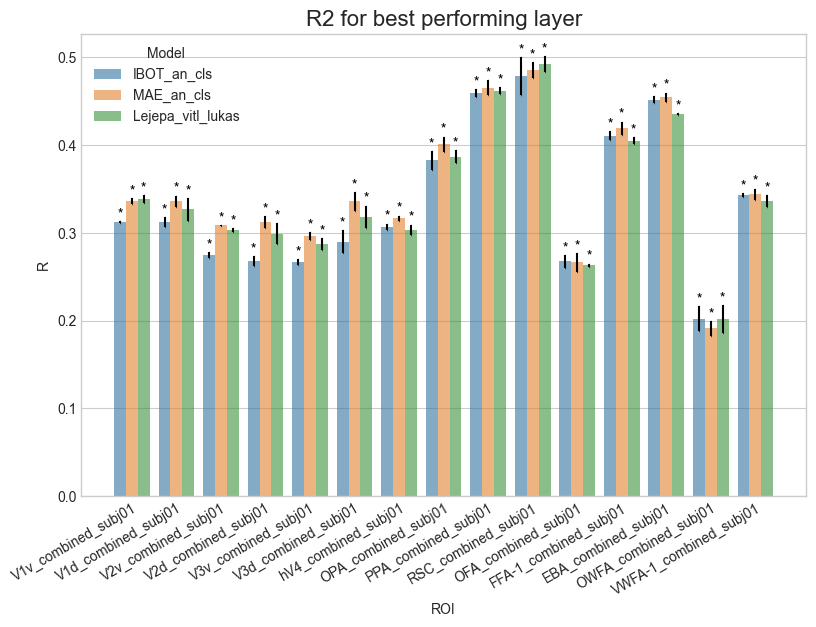

In [34]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting

le_dataframe_ibot = pd.read_csv("PATH")
le_dataframe_mae = pd.read_csv("PATH")
le_dataframe_lejepa = pd.read_csv("PATH")

plotter = Plotting([ le_dataframe_ibot,le_dataframe_mae , le_dataframe_lejepa])
results_dataframe = plotter.plot(metric="R", save_path="vitl_LE.png", model names=["LeJEPA","MAE","IBOT"])

### vit-b

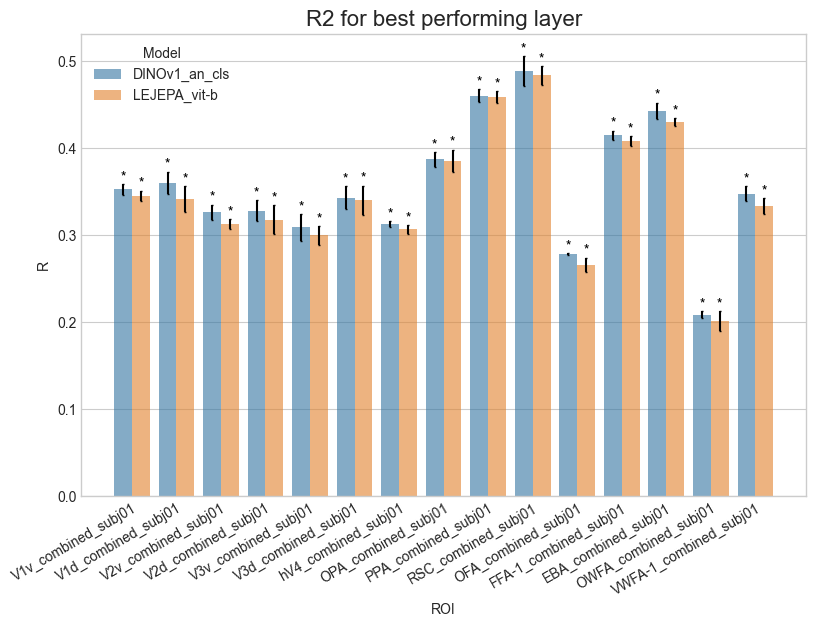

In [36]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting


le_dataframe_dino = pd.read_csv("PATH")
le_dataframe_lejepa = pd.read_csv("PATH")

plotter = Plotting([ le_dataframe_dino,le_dataframe_lejepa])
results_dataframe = plotter.plot(metric="R", save_path='vitb_LE')

### Visuin Language


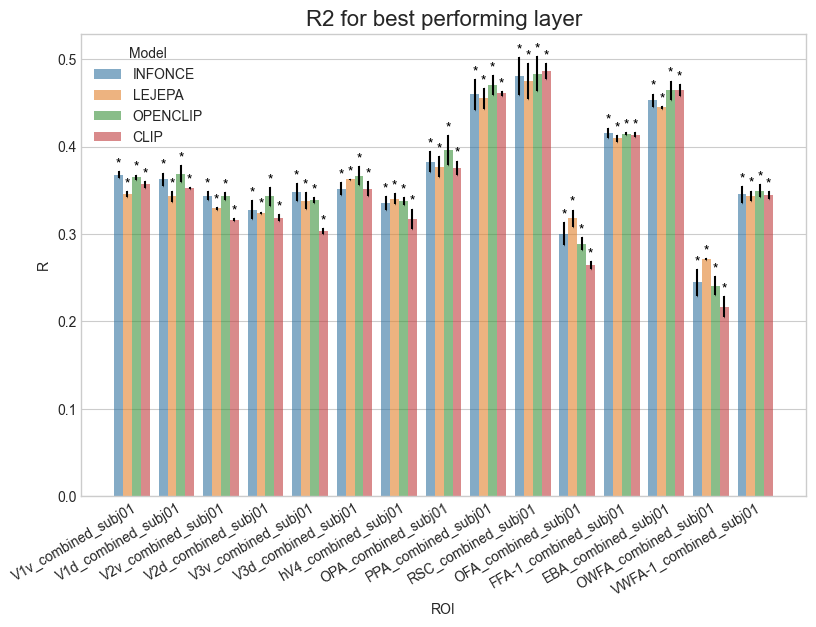

In [9]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting


le_dataframe_infonce = pd.read_csv("PATH")
le_dataframe_levljepa = pd.read_csv("PATH")
le_dataframe_openclip = pd.read_csv("PATH")
le_dataframe_clip = pd.read_csv("PATH")

plotter = Plotting([ le_dataframe_infonce,le_dataframe_levljepa, le_dataframe_openclip, le_dataframe_clip])
results_dataframe = plotter.plot(metric="R", save_path="PATH")

### video models

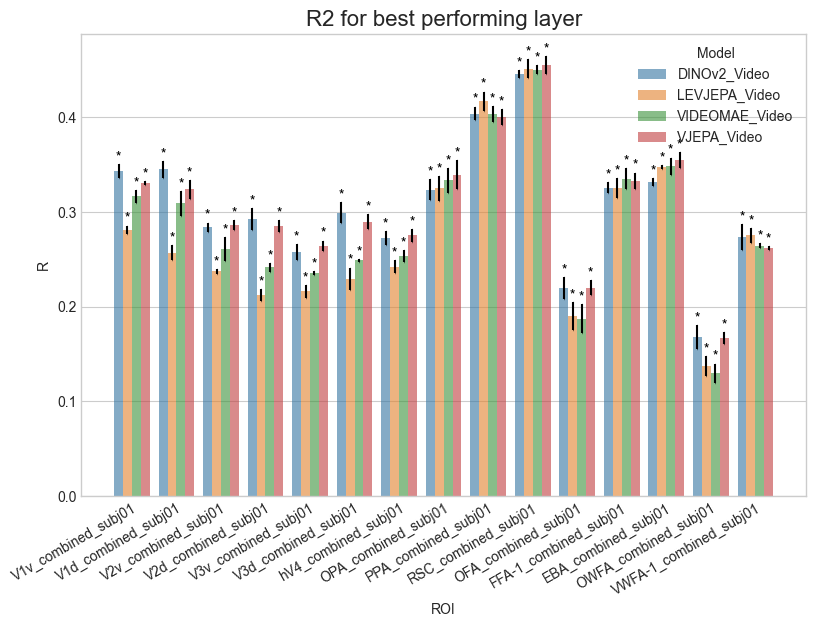

In [38]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting


dataframe_dinov2_video = pd.read_csv("PATH")

dataframe_levjepa = pd.read_csv("PATH")

dataframe_videomae = pd.read_csv("PATH")

dataframe_vjepa = pd.read_csv("PATH")

plotter = Plotting([ dataframe_dinov2_video ,dataframe_levjepa , dataframe_videomae, dataframe_vjepa])
results_dataframe = plotter.plot(metric="R",save_path='Video_LE')

### CLS

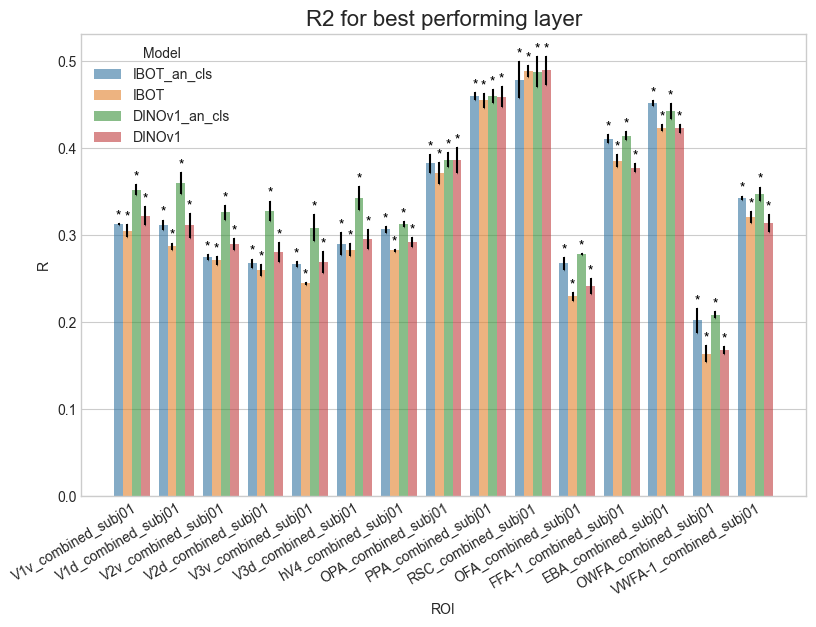

In [41]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting

le_dataframe_ibot_CLS = pd.read_csv("PATH")
le_dataframe_ibot = pd.read_csv("PATH")
le_dataframe_dino_CLS = pd.read_csv("PATH")
le_dataframe_dino = pd.read_csv("PATH")

plotter = Plotting([ le_dataframe_ibot_CLS,le_dataframe_ibot , le_dataframe_dino_CLS, le_dataframe_dino])
results_dataframe = plotter.plot(metric="R", save_path="ibot-dino-CLS_LE.png")

### ALL

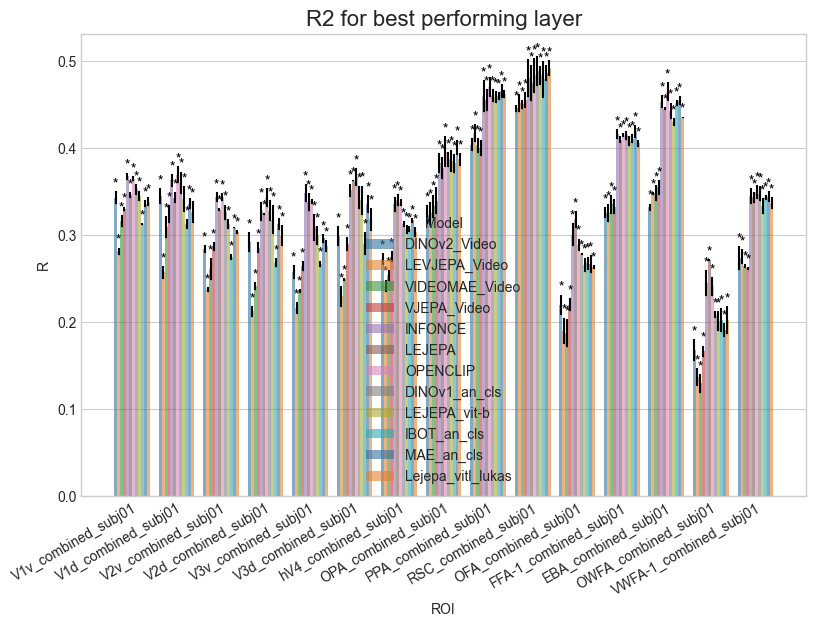

In [42]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting

#video
dataframe_dinov2_video = pd.read_csv("PATH")

dataframe_levjepa = pd.read_csv("PATH")

dataframe_videomae = pd.read_csv("PATH")

dataframe_vjepa = pd.read_csv("PATH")
# VL


le_dataframe_infonce = pd.read_csv("PATH")
le_dataframe_levljepa = pd.read_csv("PATH")
le_dataframe_openclip = pd.read_csv("PATH")
#le_dataframe_clip = pd.read_csv("PATH")

#vitb
le_dataframe_dinov1 = pd.read_csv("PATH")
le_dataframe_lejepa = pd.read_csv("PATH")

#vitl
le_dataframe_ibot = pd.read_csv("PATH")
le_dataframe_mae = pd.read_csv("PATH")
le_dataframe_lejepa_vitl = pd.read_csv("PATH")

plotter = Plotting([ dataframe_dinov2_video ,dataframe_levjepa , dataframe_videomae, dataframe_vjepa, le_dataframe_infonce, le_dataframe_levljepa, le_dataframe_openclip, 
                   le_dataframe_dinov1, le_dataframe_lejepa, le_dataframe_ibot, le_dataframe_mae, le_dataframe_lejepa_vitl])
results_dataframe = plotter.plot(metric="R",save_path='all_LE')

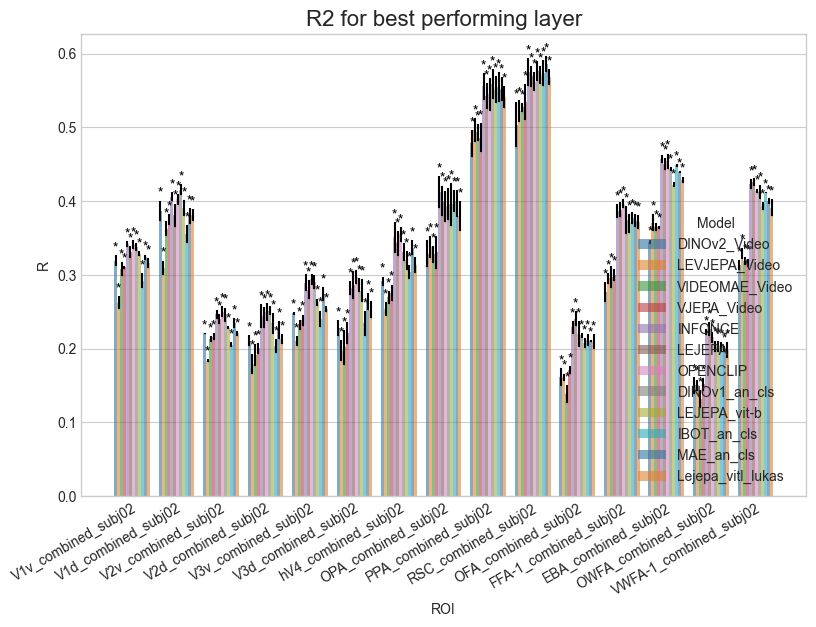

In [44]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting

#video
dataframe_dinov2_video = pd.read_csv("PATH")

dataframe_levjepa = pd.read_csv("PATH")

dataframe_videomae = pd.read_csv("PATH")

dataframe_vjepa = pd.read_csv("PATH")
# VL


le_dataframe_infonce = pd.read_csv("PATH")
le_dataframe_levljepa = pd.read_csv("PATH")
le_dataframe_openclip = pd.read_csv("PATH")
#le_dataframe_clip = pd.read_csv("PATH")

#vitb
le_dataframe_dinov1 = pd.read_csv("PATH")
le_dataframe_lejepa = pd.read_csv("PATH")

#vitl
le_dataframe_ibot = pd.read_csv("PATH")
le_dataframe_mae = pd.read_csv("PATH")
le_dataframe_lejepa_vitl = pd.read_csv("PATH")

plotter = Plotting([ dataframe_dinov2_video ,dataframe_levjepa , dataframe_videomae, dataframe_vjepa, le_dataframe_infonce, le_dataframe_levljepa, le_dataframe_openclip, 
                   le_dataframe_dinov1, le_dataframe_lejepa, le_dataframe_ibot, le_dataframe_mae, le_dataframe_lejepa_vitl])
results_dataframe = plotter.plot(metric="R",save_path='all_LE_subj2')

### dif subj

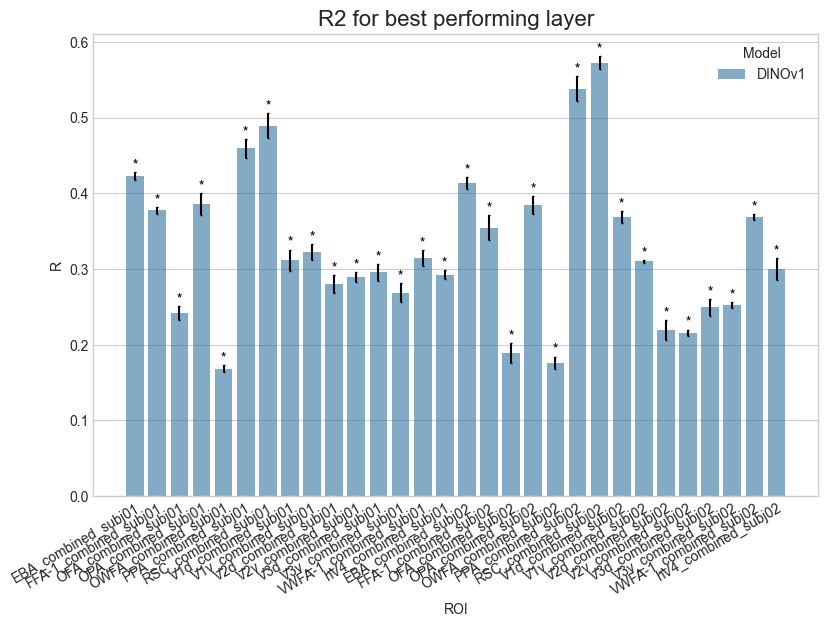

In [6]:
import pandas as pd
from net2brain.evaluations.plotting import Plotting

dataframe_dino1 = pd.read_csv("PATH")
dataframe_dino2 = pd.read_csv("PATH")
#dataframe_dino3 = pd.read_csv("PATH")
#dataframe_dino4 = pd.read_csv("PATH")
#dataframe_dino5 = pd.read_csv("PATH")

plotter = Plotting([dataframe_dino1, dataframe_dino2 ])
results_dataframe = plotter.plot(metric="R")